# МОМО: лабораторная № 1

## Численные методы линейной алгебры в задаче наименьших квадратов

# 1.1 Цель работы

Исследовать влияние ранга и обусловленности матрицы данных на численное решение задачи наи-
меньших квадратов; сопоставить прямой, итерационный и спектральный способы решения; изучить
действие сокращения размерности и регуляризации.
Работа строится как единый вычислительный эксперимент. Все сравниваемые методы используют
одно разбиение данных и согласованный способ подготовки признаков.

# 1.2 Исходные данные

## Superconductors: предсказание критической температуры

**Задача регрессии:** по числовым характеристикам химического состава материала предсказать его критическую температуру `critical_temp` в кельвинах (К). При охлаждении ниже этой температуры материал переходит в сверхпроводящее состояние. Данные содержат сведения об известных сверхпроводниках.

Одна строка — запись о материале. Файл `train.csv` содержит полный набор: **21 263 наблюдения, 81 входной признак и 1 целевой столбец**, пропуски отсутствуют по описанию UCI. В экспериментах используются **8 вещественных признаков**: средние арифметические каждого из восьми свойств элементов (`mean_...`). Эти столбцы уже рассчитаны автором набора. В пункте 1.4.5 к ним добавим искусственный признак для эксперимента с потерей ранга.

| Переменная | Роль | Тип | Смысл |
|---|---|---|---|
| `critical_temp` | Целевая переменная `y` | Вещественная | Экспериментальная критическая температура, К |
| Выбранные 8 столбцов `mean_...` | Признаки `X` | Вещественные | Средние арифметические свойств различных элементов в составе |

Целевой столбец исключается из `X` и не используется при вычислении исходных признаков: они получены из состава и свойств элементов, а температура — из экспериментальных данных.

**Источники:** [Kaggle: Superconductors](https://www.kaggle.com/datasets/anlgrbz/super-conductors), [UCI: Superconductivty Data](https://archive.ics.uci.edu/dataset/464/superconductivty+data). Автор подготовленного набора — Kam Hamidieh; исходные сведения собраны из NIMS SuperCon. Очистка и расчёт признаков описаны в [статье автора, раздел 2](https://arxiv.org/html/1803.10260).

## Восемь выбранных признаков

Для каждого свойства **химических элементов, входящих в материал**, оставляем только среднее арифметическое. Это готовые агрегаты по различным элементам состава, без учёта их долей. Например, `mean_Density` — среднее плотностей элементов, а не прямое измерение плотности самого материала.

| Используемый столбец | Свойство элемента | Единицы исходного свойства | Смысл |
|---|---|---|---|
| `mean_atomic_mass` | Атомная масса | а.е.м. | Масса атома |
| `mean_fie` | Энергия первой ионизации | кДж/моль | Энергия удаления первого электрона |
| `mean_atomic_radius` | Атомный радиус | пм | Размер атома |
| `mean_Density` | Плотность | кг/м³ | Масса на единицу объёма при стандартных условиях |
| `mean_ElectronAffinity` | Сродство к электрону | кДж/моль | Энергетическая характеристика присоединения электрона |
| `mean_FusionHeat` | Теплота плавления | кДж/моль | Энергия перехода из твёрдого состояния в жидкое |
| `mean_ThermalConductivity` | Теплопроводность | Вт/(м·К) | Способность проводить тепло |
| `mean_Valence` | Валентность | Безразмерная | Типичное число образуемых химических связей |

Единицы указаны для базовых свойств. Энтропия — безразмерная производная характеристика. При подготовке исходного набора автор добавил 1,5 к значениям сродства к электрону для корректного расчёта логарифмов. [Описание базовых свойств](https://arxiv.org/html/1803.10260#S2.SS1).


## Характеристики исходного набора и выбор признаков

Для каждого из восьми свойств уже рассчитаны следующие десять характеристик. Взвешенные версии учитывают доли элементов в химической формуле. Подробные определения, включая специальные формулы взвешенной энтропии и размаха, приведены в [разделе 2.3 статьи](https://arxiv.org/html/1803.10260#S2.SS3).

| Префикс | Характеристика | Что описывает | Пример столбца |
|---|---|---|---|
| `mean_` | Среднее арифметическое | Средний уровень свойства по различным элементам | `mean_atomic_mass` |
| `wtd_mean_` | Взвешенное среднее | Средний уровень с учётом долей элементов | `wtd_mean_atomic_mass` |
| `gmean_` | Среднее геометрическое | Мультипликативное усреднение значений | `gmean_atomic_mass` |
| `wtd_gmean_` | Взвешенное геометрическое среднее | Геометрическое усреднение с учётом долей | `wtd_gmean_atomic_mass` |
| `entropy_` | Энтропия | Равномерность нормированных значений свойства | `entropy_atomic_mass` |
| `wtd_entropy_` | Взвешенная энтропия | Равномерность с учётом долей элементов | `wtd_entropy_atomic_mass` |
| `range_` | Размах | Разность максимального и минимального значений | `range_atomic_mass` |
| `wtd_range_` | Взвешенный размах | Размах значений после умножения на доли элементов | `wtd_range_atomic_mass` |
| `std_` | Стандартное отклонение | Разброс значений вокруг среднего | `std_atomic_mass` |
| `wtd_std_` | Взвешенное стандартное отклонение | Разброс с учётом долей элементов | `wtd_std_atomic_mass` |

В исходном CSV: 8 свойств × 10 характеристик + `number_of_elements` = **81 признак**. Для этой работы из них выбираются **только 8 столбцов `mean_...`**, перечисленных выше. Другие агрегаты и `number_of_elements` в матрицу `X` не включаются. Выбор фиксирован до разбиения и не зависит от целевой переменной.


Оставим только базовые признаки среднего для упрощения

# 1.3 Постановка задачи

Для обучающей матрицы $X \in \mathbb{R}^{n \times p}$ и вектора ответов $y \in \mathbb{R}^{n}$ рассматривается задача:

$$
\min_{\beta \in \mathbb{R}^{p}} \|X\beta - y\|_2^2.
$$

Соответствующие нормальные уравнения:

$$
A\beta = b, \qquad A = X^{T}X, \qquad b = X^{T}y.
$$

Основной показатель качества прогноза — **RMSE на тестовой части**:

$$
\operatorname{RMSE}
=
\sqrt{\frac{1}{n_{\text{test}}}
\sum_{i=1}^{n_{\text{test}}}(y_i - \hat{y}_i)^2}.
$$

# 1.4 Обязательная часть

## Установка зависимостей, загрузка датасета и деление данных

Запускайте ячейки сверху вниз в Jupyter, VS Code, Google Colab или Kaggle. Требуется **Python 3.10+** и доступ в интернет. Команда `%pip` устанавливает библиотеки в окружение текущего ядра.

In [1]:
%pip install -q "kagglehub>=1.0.3" pandas numpy "scikit-learn>=1.2" matplotlib


Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
from IPython.display import display

DATASET_HANDLE = "anlgrbz/super-conductors/versions/1"
CSV_NAME = "train.csv"

csv_path = Path(kagglehub.dataset_download(DATASET_HANDLE, path=CSV_NAME))
print(f"CSV загружен: {csv_path}")


/home/andrei/.cache/momo143-venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CSV загружен: /home/andrei/.cache/kagglehub/datasets/anlgrbz/super-conductors/versions/1/train.csv


In [3]:
df = pd.read_csv(csv_path)

print(f"Наблюдений: {df.shape[0]:,}")
print(f"Столбцов: {df.shape[1]}")
display(df.head())


Наблюдений: 21,263
Столбцов: 82


,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944468,57.862692,66.361592,36.116612,1.181795,1.062396,122.90607,31.794921,51.968828,...,2.257143,2.213364,2.219783,1.368922,1.066221,1,1.085714,0.433013,0.437059,29.0
1,5,92.729214,58.518416,73.132787,36.396602,1.449309,1.057755,122.90607,36.161939,47.094633,...,2.257143,1.888175,2.210679,1.557113,1.047221,2,1.128571,0.632456,0.468606,26.0
2,4,88.944468,57.885242,66.361592,36.122509,1.181795,0.975980,122.90607,35.741099,51.968828,...,2.271429,2.213364,2.232679,1.368922,1.029175,1,1.114286,0.433013,0.444697,19.0
3,4,88.944468,57.873967,66.361592,36.119560,1.181795,1.022291,122.90607,33.768010,51.968828,...,2.264286,2.213364,2.226222,1.368922,1.048834,1,1.100000,0.433013,0.440952,22.0
4,4,88.944468,57.840143,66.361592,36.110716,1.181795,1.129224,122.90607,27.848743,51.968828,...,2.242857,2.213364,2.206963,1.368922,1.096052,1,1.057143,0.433013,0.428809,23.0


In [4]:
TARGET = "critical_temp"

assert TARGET in df.columns, f"В CSV отсутствует целевой столбец {TARGET!r}."
assert df.shape == (21263, 82), f"Неожиданный размер таблицы: {df.shape}"
assert df.select_dtypes(include="number").shape[1] == df.shape[1], "Есть нечисловые столбцы."
assert not df.isna().any().any(), "В данных обнаружены пропуски."

print(f"Признаков в исходном CSV: {df.shape[1] - 1}")
print(f"Пропусков: {int(df.isna().sum().sum())}")
print(f"Целевая переменная: {TARGET}")


Признаков в исходном CSV: 81
Пропусков: 0
Целевая переменная: critical_temp


In [5]:
SEED = 42
TRAIN_FRACTION = 0.70
VAL_FRACTION = 0.15
TEST_FRACTION = 0.15

FEATURES = [
    "mean_atomic_mass",
    "mean_fie",
    "mean_atomic_radius",
    "mean_Density",
    "mean_ElectronAffinity",
    "mean_FusionHeat",
    "mean_ThermalConductivity",
    "mean_Valence",
]

X = df[FEATURES].copy()
y = df[TARGET]

rng = np.random.default_rng(SEED)
shuffled_indices = rng.permutation(df.index.to_numpy())
n_train = int(len(df) * TRAIN_FRACTION)
n_val = int(len(df) * VAL_FRACTION)

train_indices = shuffled_indices[:n_train]
val_indices = shuffled_indices[n_train:n_train + n_val]
test_indices = shuffled_indices[n_train + n_val:]

X_train, X_val, X_test = (X.loc[idx].copy() for idx in (train_indices, val_indices, test_indices))
y_train, y_val, y_test = (y.loc[idx].copy() for idx in (train_indices, val_indices, test_indices))


In [6]:
assert df.index.is_unique, "Для разбиения нужны уникальные индексы строк."
assert np.isclose(TRAIN_FRACTION + VAL_FRACTION + TEST_FRACTION, 1.0)
assert len(X_train) + len(X_val) + len(X_test) == len(df)
assert X_train.index.intersection(X_val.index).empty
assert X_train.index.intersection(X_test.index).empty
assert X_val.index.intersection(X_test.index).empty
assert set(X_train.index) | set(X_val.index) | set(X_test.index) == set(df.index)

for features, target in ((X_train, y_train), (X_val, y_val), (X_test, y_test)):
    assert features.index.equals(target.index), "Индексы признаков и цели не совпадают."
    assert TARGET not in features.columns, "Целевой столбец попал в признаки."

split_summary = pd.DataFrame({
    "Подвыборка": ["train", "val", "test"],
    "Наблюдений": [len(X_train), len(X_val), len(X_test)],
    "Признаков": [X_train.shape[1], X_val.shape[1], X_test.shape[1]],
})
split_summary["Доля, %"] = (split_summary["Наблюдений"] / len(df) * 100).round(2)

print(f"Seed: {SEED}")
display(split_summary)


Seed: 42


,Подвыборка,Наблюдений,Признаков,"Доля, %"
0,train,14884,8,70.0
1,val,3189,8,15.0
2,test,3190,8,15.0


Определим матрицы A и b для трейновой части

In [7]:
A_train = X_train.T @ X_train
b_train = X_train.T @ y_train

## 1.4.1 Исследование матрицы данных

Для исходной и стандартизованной матриц используем SVD и одно правило численного ранга:

$$
\tau = \sigma_{\max}\max(n,p)\varepsilon_{\mathrm{mach}},
\qquad r_{\mathrm{num}} = \#\{i:\sigma_i>\tau\}.
$$

Фактический допуск вычисляется отдельно для каждой матрицы. Число обусловленности в норме 2 определяется отношением максимального сингулярного числа к минимальному. При полном столбцовом ранге в точной арифметике $\kappa_2(X^TX)=\kappa_2(X)^2$

In [8]:
from sklearn.preprocessing import StandardScaler

In [9]:
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)

In [10]:
eigenvalues = np.linalg.eigvalsh(A_train)

singular_values = np.linalg.svd(X_train, compute_uv=False)
singular_values_std = np.linalg.svd(X_train_std, compute_uv=False)

tol = singular_values[0] * max(X_train.shape) * np.finfo(singular_values.dtype).eps
tol_std = singular_values_std[0] * max(X_train_std.shape) * np.finfo(singular_values_std.dtype).eps

rank = np.count_nonzero(singular_values > tol)
rank_std = np.count_nonzero(singular_values_std > tol_std)

A_train_std = X_train_std.T @ X_train_std
eigenvalues_std = np.linalg.eigvalsh(A_train_std)

cond_X_train = singular_values[0] / singular_values[-1] if singular_values[-1] > 0 else np.inf
cond_X_train_std = singular_values_std[0] / singular_values_std[-1] if singular_values_std[-1] > 0 else np.inf

cond_A_train = cond_X_train ** 2
cond_A_train_std = cond_X_train_std ** 2

cond_A_train_eig = eigenvalues[-1] / eigenvalues[0] if eigenvalues[0] > 0 else np.inf
cond_A_train_std_eig = eigenvalues_std[-1] / eigenvalues_std[0] if eigenvalues_std[0] > 0 else np.inf

relative_difference_A_train = abs(cond_A_train_eig - cond_A_train) / cond_A_train if np.isfinite(cond_A_train_eig) and np.isfinite(cond_A_train) else np.nan
relative_difference_A_train_std = abs(cond_A_train_std_eig - cond_A_train_std) / cond_A_train_std if np.isfinite(cond_A_train_std_eig) and np.isfinite(cond_A_train_std) else np.nan

matrix_diagnostics = pd.DataFrame({
    "Матрица": ["До стандартизации", "После стандартизации"],
    "Наблюдений": [X_train.shape[0], X_train_std.shape[0]],
    "Признаков": [X_train.shape[1], X_train_std.shape[1]],
    "Допуск": [tol, tol_std],
    "Численный ранг": [rank, rank_std],
    "κ₂(X)": [cond_X_train, cond_X_train_std],
    "κ₂(XᵀX)": [cond_A_train, cond_A_train_std],
    "λ_max / λ_min": [cond_A_train_eig, cond_A_train_std_eig],
    "Относительное различие": [relative_difference_A_train, relative_difference_A_train_std],
})

with pd.option_context("display.float_format", "{:.6e}".format, "display.max_columns", None):
    display(matrix_diagnostics)


,Матрица,Наблюдений,Признаков,Допуск,Численный ранг,κ₂(X),κ₂(XᵀX),λ_max / λ_min,Относительное различие
0,До стандартизации,14884,8,2.735261e-06,8,1.250998e+04,1.564997e+08,1.564997e+08,1.142583e-14
1,После стандартизации,14884,8,6.677926e-10,8,6.654204e+00,4.427844e+01,4.427844e+01,1.139348e-14


Обе матрицы имеют численный ранг равный количеству признаков при заданном допуске, что говорит о том, что коллинеарных признаков нет. Число обусловленности kappa_2(X) и kappa_2(X^T@X) уменьшается после стандартизации X, так как стандартизация центрировала признаки и привела их к сопоставимому масштабу и в результате матрица стала более равномерно растягивать разные направления

### Сингулярные числа


In [11]:
singular_values_table = pd.DataFrame({
    "Номер": np.arange(1, len(singular_values) + 1),
    "До стандартизации": singular_values,
    "После стандартизации": singular_values_std,
})

with pd.option_context("display.max_rows", None):
    display(singular_values_table)


,Номер,До стандартизации,После стандартизации
0,1,827635.041276,202.060640
1,2,43604.774072,176.373633
2,3,5096.287955,129.671406
3,4,3843.193378,121.163314
4,5,2834.127196,83.259186
5,6,1964.601062,67.083801
6,7,1054.731490,57.325417
7,8,66.157959,30.365860


Также стандартизация уменьшила абсолютные значения сингулярных значений, так как стандарттзация уменьшила масштаб признаков

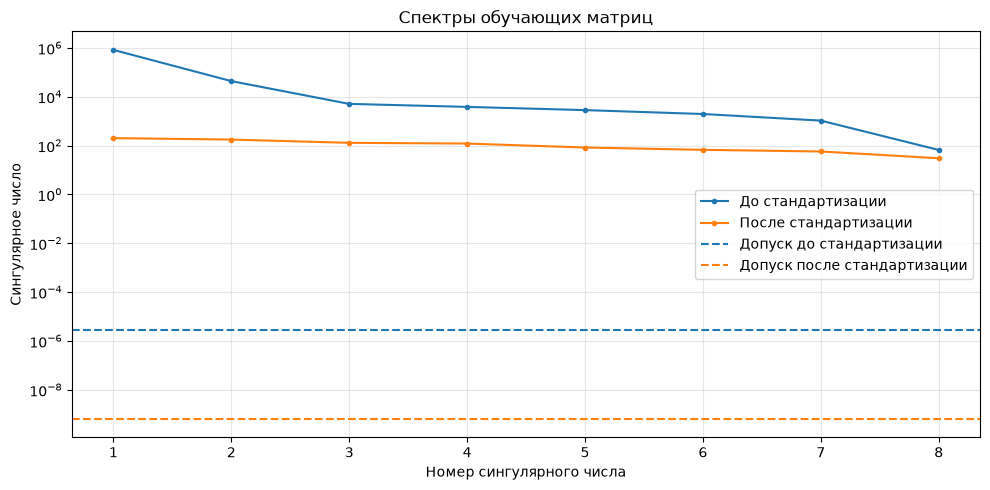

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
ax.semilogy(singular_values_table["Номер"], singular_values, "o-", markersize=3, label="До стандартизации")
ax.semilogy(singular_values_table["Номер"], singular_values_std, "o-", markersize=3, label="После стандартизации")
ax.axhline(tol, color="tab:blue", linestyle="--", label="Допуск до стандартизации")
ax.axhline(tol_std, color="tab:orange", linestyle="--", label="Допуск после стандартизации")
ax.set(xlabel="Номер сингулярного числа", ylabel="Сингулярное число", title="Спектры обучающих матриц")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


ИЗ графика видно, что после стандартизации сингулярные числа стали примерно одного порядка и разброс уменьшился, так как сингулярные направления матрицы X были отмасштиброваны и влияние в разницах масштаба уменьшилось

### Корреляционные матрицы количественных признаков

Корреляции Пирсона рассчитываются по обучающей части для 8 выбранных признаков. Положительное масштабирование и центрирование сохраняют корреляции, поэтому матрицы до и после StandardScaler должны совпадать с точностью до округления.


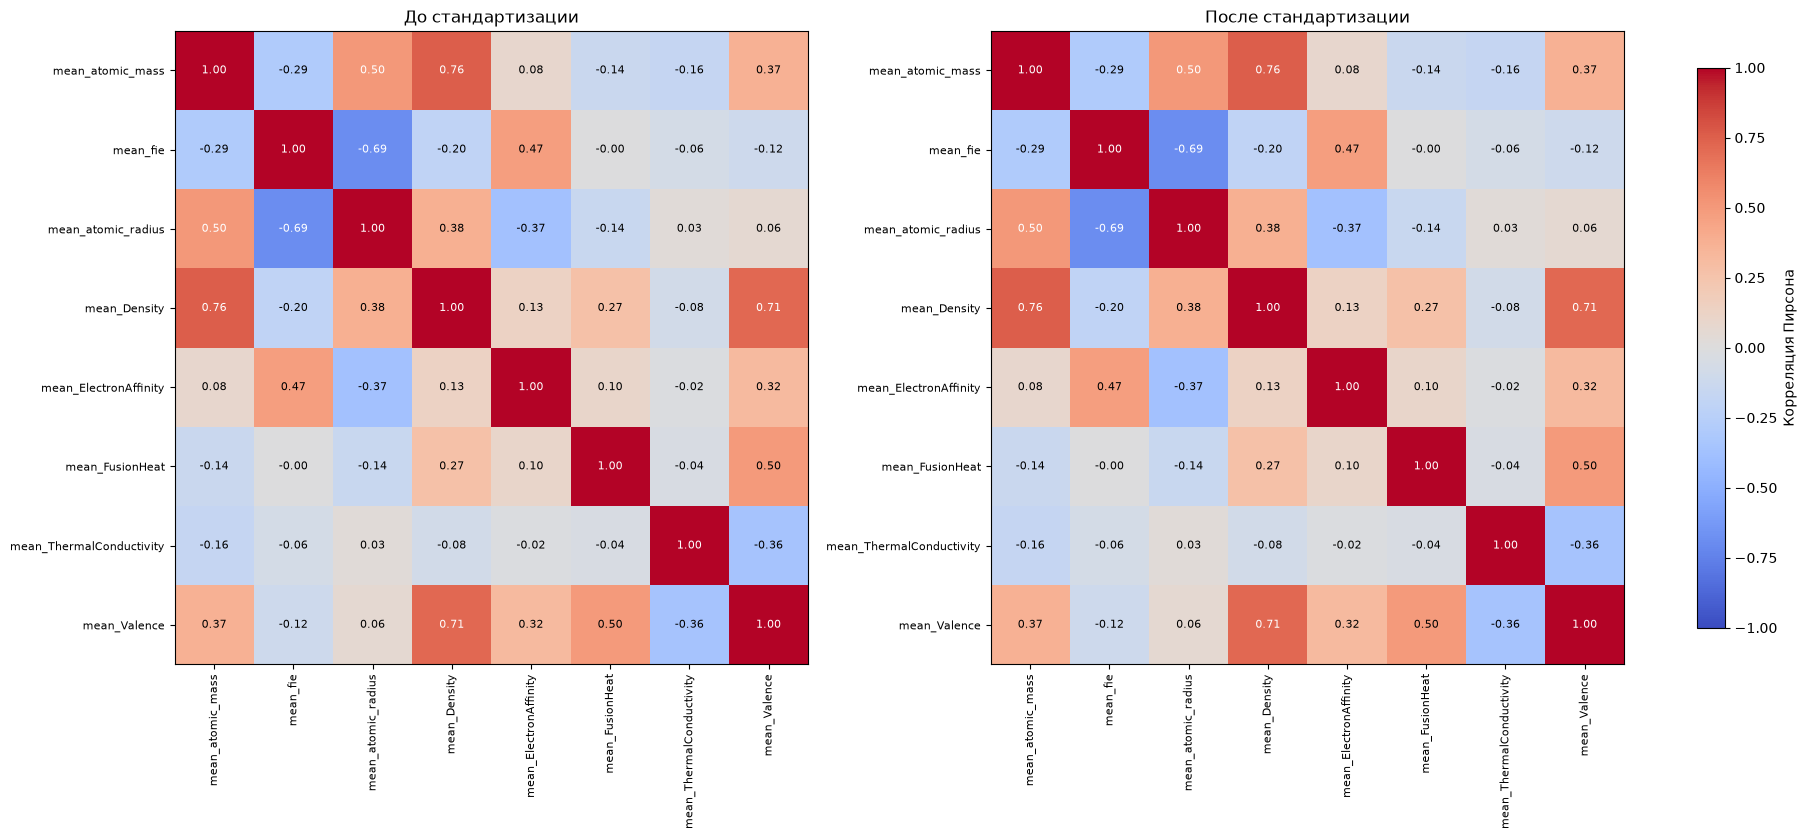

Максимальное различие корреляций: 7.549516567451064e-15


In [13]:
X_train_std_df = pd.DataFrame(X_train_std, index=X_train.index, columns=X_train.columns)

corr_train = X_train.corr(method="pearson")
corr_train_std = X_train_std_df.corr(method="pearson")

fig, axes = plt.subplots(1, 2, figsize=(18, 9), layout="constrained")
for ax, corr, title in zip(
    axes,
    (corr_train, corr_train_std),
    ("До стандартизации", "После стандартизации"),
):
    image = ax.imshow(corr.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
    ticks = np.arange(len(corr.columns))
    ax.set_xticks(ticks, labels=corr.columns, rotation=90, fontsize=8)
    ax.set_yticks(ticks, labels=corr.index, fontsize=8)
    ax.set_title(title)
    for row in range(len(corr)):
        for col in range(len(corr.columns)):
            value = corr.iloc[row, col]
            ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(value) > 0.5 else "black")

fig.colorbar(image, ax=axes, shrink=0.7, label="Корреляция Пирсона")
plt.show()

print("Максимальное различие корреляций:", np.max(np.abs(corr_train.to_numpy() - corr_train_std.to_numpy())))


Корреляции до и после стандартизации не отличаются, так как стандартизация не меняет линейную зависимость между признаками. Прямой линейной зависимости между признаками нет.

### Вывод об обусловленности и мультиколлинеарности

Численный ранг до и после стандартизации матрицы равен 8, то есть полному рангу. Использованы вычисленные допуски 2,74·10⁻⁶ и 6,68·10⁻¹⁰ соответственно. Прямой линейной зваисимости между признаками не выявлено.

До стандартизации число обусловленности **κ₂(X) ≈ 1,25·10⁴**, а для матрицы нормальных уравнений **κ₂(XᵀX) ≈ 1,56·10⁸**. После стандартизации эти значения снижаются до **6,65** и **44,28** соответственно. Ээто указывает на то, что стандартизованная матрица имеет значительно более благоприятную обусловленность, что важно для сходимости градиентных методов и решения нормального уравнения.

Стандартизация сохраняет корреляции Пирсона. Улучшение обусловленности связано с центрированием и изменением масштабов, а не с устранением корреляций. Дальнейшие эксперименты проводятся на стандартизованных признаках.


## 1.4.2. Прямое решение нормальных уравнений


### Метод Гаусса с частичным выбором ведущего элемента

К восьми стандартизованным признакам добавляем столбец единиц для свободного члена. Получаем матрицу $\widetilde X=[\mathbf{1}\;X_{train,std}]$ с девятью столбцами и решаем нормальные уравнения:

$$
A\beta=b,\qquad A=\widetilde X^T\widetilde X,\qquad b=\widetilde X^Ty_{train}.
$$

Цель не центрируем. В этом разделе не переобучаем `scaler`; тестовую часть преобразуем с параметрами train. `A_train` и `b_train` относятся к исходным признакам и для этого решения не используются.

Прямой ход: в столбце $k$ выбираем строку с максимальным модулем элемента среди строк $k,\ldots,p-1$, переставляем строки матрицы и правой части, затем зануляем элементы ниже диагонали:

$$
r=\arg\max_{i\geq k}|a_{ik}|,\qquad
m_{ik}=\frac{a_{ik}}{a_{kk}},\qquad
A_{i,:}\leftarrow A_{i,:}-m_{ik}A_{k,:},\qquad
b_i\leftarrow b_i-m_{ik}b_k.
$$

После получения верхнетреугольной системы коэффициенты восстанавливаются обратной подстановкой. Расчёт выполняется на копиях входов; исходные $A,b$ сохраняются для метрик и Холецкого. Явная обратная матрица не вычисляется.

Допуск малого ведущего элемента фиксируем относительно исходной матрицы:

$$
\tau_{pivot}=\text{rtol}\,\|A\|_\infty,\qquad
\text{rtol}=p\,\varepsilon_{mach}.
$$

Если максимальный кандидат не превышает этот порог, метод останавливается с объяснением; остальные сравнения продолжаются. Этот порог относится к ведущим элементам и отличается от допуска численного ранга из 1.4.1.


In [14]:
X_train_direct = np.column_stack((
    np.ones(len(X_train_std)), np.asarray(X_train_std, dtype=np.float64)
))
X_test_direct = np.column_stack((
    np.ones(len(X_test)), scaler.transform(X_test)
))
coefficient_names_direct = ["Свободный член"] + FEATURES
y_train_direct = y_train.to_numpy(dtype=np.float64)
y_test_direct = y_test.to_numpy(dtype=np.float64)

# Собственная матрица 9×9: A_train_std из 1.4.1 остаётся матрицей восьми признаков.
A_gauss = X_train_direct.T @ X_train_direct
b_gauss = X_train_direct.T @ y_train_direct
gauss_rtol = A_gauss.shape[0] * np.finfo(A_gauss.dtype).eps
gauss_pivot_tol = gauss_rtol * np.linalg.norm(A_gauss, ord=np.inf)

print(f"Размер системы со свободным членом: {A_gauss.shape}")
print(f"Относительный допуск ведущего элемента: {gauss_rtol:.6e}")
print(f"Абсолютный порог ведущего элемента: {gauss_pivot_tol:.6e}")


Размер системы со свободным членом: (9, 9)
Относительный допуск ведущего элемента: 1.998401e-15
Абсолютный порог ведущего элемента: 1.048110e-10


In [15]:
def gaussian_solve(A, b, rtol=None):
    U = np.array(A, dtype=np.float64, copy=True)
    rhs = np.array(b, dtype=np.float64, copy=True)
    if U.ndim != 2 or U.shape[0] != U.shape[1] or rhs.ndim != 1:
        raise ValueError("Нужны квадратная матрица и одномерная правая часть.")
    if rhs.size == 0 or U.shape[0] != rhs.size:
        raise ValueError("Размеры матрицы и правой части не согласованы.")
    if not np.isfinite(U).all() or not np.isfinite(rhs).all():
        raise ValueError("Входные данные должны быть конечными.")

    n = rhs.size
    if rtol is None:
        rtol = n * np.finfo(U.dtype).eps
    if not np.isfinite(rtol) or rtol < 0:
        raise ValueError("Относительный допуск должен быть конечным и неотрицательным.")
    pivot_tol = rtol * np.linalg.norm(U, ord=np.inf)

    with np.errstate(over="raise", divide="raise", invalid="raise"):
        for k in range(n):
            pivot = k + np.argmax(np.abs(U[k:, k]))
            if abs(U[pivot, k]) <= pivot_tol:
                raise np.linalg.LinAlgError(
                    f"Малый ведущий элемент на шаге {k + 1}: "
                    f"{abs(U[pivot, k]):.6e} <= {pivot_tol:.6e}"
                )
            if pivot != k:
                U[[k, pivot]] = U[[pivot, k]]
                rhs[[k, pivot]] = rhs[[pivot, k]]
            for i in range(k + 1, n):
                multiplier = U[i, k] / U[k, k]
                U[i, k + 1:] -= multiplier * U[k, k + 1:]
                rhs[i] -= multiplier * rhs[k]
                U[i, k] = 0.0

        beta = np.zeros(n)
        for i in range(n - 1, -1, -1):
            beta[i] = (rhs[i] - U[i, i + 1:] @ beta[i + 1:]) / U[i, i]

    if not np.isfinite(beta).all():
        raise FloatingPointError("Получены нечисловые коэффициенты.")
    return beta


### Решение Гауссом и библиотечный эталон

Для эталона используем [`numpy.linalg.solve`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.solve.html), решающий ту же систему с теми же $A,b$. Численные неудачи сохраняются в статусах, а не прерывают остальные методы.


In [16]:
beta_gauss = None
beta_reference = None
direct_status = {}

try:
    beta_gauss = gaussian_solve(A_gauss, b_gauss, rtol=gauss_rtol)
    direct_status["Гаусс"] = "Успех"
except (np.linalg.LinAlgError, FloatingPointError) as error:
    direct_status["Гаусс"] = str(error)

beta_direct = beta_gauss

try:
    beta_reference = np.linalg.solve(A_gauss, b_gauss)
    if not np.isfinite(beta_reference).all():
        raise FloatingPointError("Получены нечисловые коэффициенты.")
    direct_status["numpy.linalg.solve"] = "Успех"
except (np.linalg.LinAlgError, FloatingPointError) as error:
    beta_reference = None
    direct_status["numpy.linalg.solve"] = str(error)

for method, status in direct_status.items():
    print(f"{method}: {status}")


Гаусс: Успех
numpy.linalg.solve: Успех


### Проверка разложения Холецкого

разложение Холецкого существует и единственно тогда и только тогда, когда матрица A = L @ L^T симметрична и положительно определена.

Пробуем [`numpy.linalg.cholesky`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.cholesky.html). При успехе решаем $Lu=b$ и $L^T\beta=u$ с помощью [`scipy.linalg.solve_triangular`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.solve_triangular.html). При неудаче фиксируем исключение и сопоставляем его с рангом, спектром и обусловленностью.


In [17]:
from scipy.linalg import solve_triangular

A_direct_eigenvalues = np.linalg.eigvalsh(A_gauss)
A_direct_properties = pd.DataFrame([{
    "Симметрична": np.allclose(A_gauss, A_gauss.T),
    "Ранг матрицы со свободным членом": np.linalg.matrix_rank(X_train_direct),
    "Размер A": A_gauss.shape[0],
    "λ_min(A)": A_direct_eigenvalues[0],
    "λ_max(A)": A_direct_eigenvalues[-1],
    "κ₂(A)": np.linalg.cond(A_gauss),
}])
with pd.option_context("display.max_columns", None):
    display(A_direct_properties)

beta_cholesky = None
cholesky_reconstruction_error = np.nan

try:
    L_cholesky = np.linalg.cholesky(A_gauss)
    intermediate_cholesky = solve_triangular(L_cholesky, b_gauss, lower=True)
    beta_cholesky = solve_triangular(L_cholesky.T, intermediate_cholesky, lower=False)
    if not np.isfinite(beta_cholesky).all():
        raise FloatingPointError("Получены нечисловые коэффициенты.")
    cholesky_reconstruction_error = (
        np.linalg.norm(A_gauss - L_cholesky @ L_cholesky.T) / np.linalg.norm(A_gauss)
    )
    direct_status["Холецкий"] = "Успех"
except (np.linalg.LinAlgError, FloatingPointError) as error:
    beta_cholesky = None
    direct_status["Холецкий"] = str(error)

print(f"Холецкий: {direct_status['Холецкий']}")
print(f"Относительная ошибка восстановления A: {cholesky_reconstruction_error:.6e}")


,Симметрична,Ранг матрицы со свободным членом,Размер A,λ_min(A),λ_max(A),κ₂(A)
0,True,9,9,922.085447,40828.502041,44.278437


Холецкий: Успех
Относительная ошибка восстановления A: 7.936457e-17


### Коэффициенты и сравнение методов

Для каждого успешного решения вычисляем:

$$
r_{NE}=\frac{\|A\beta-b\|_2}{\|b\|_2},\qquad
r_{LS}=\frac{\|\widetilde X\beta-y_{train}\|_2}{\|y_{train}\|_2},
$$

$$
\operatorname{RMSE}_{train/test}
=\sqrt{\frac1m\sum_{i=1}^{m}(\hat y_i-y_i)^2},\qquad
\delta_\beta=\frac{\|\beta-\beta_{reference}\|_2}{\|\beta_{reference}\|_2}.
$$

Все нормы в относительных остатках — евклидовы. При нулевом знаменателе сохраняем абсолютную норму. Для неуспешного метода метрики остаются `NaN`, причина приведена в статусе. Первый коэффициент — свободный член, остальные относятся к стандартизованным признакам; RMSE — к исходной шкале цели в кельвинах.


In [18]:
def relative_norm(residual, reference):
    denominator = np.linalg.norm(reference)
    return np.linalg.norm(residual) / denominator if denominator > 0 else np.linalg.norm(residual)


direct_solutions = {
    "Гаусс": beta_gauss,
    "numpy.linalg.solve": beta_reference,
    "Холецкий": beta_cholesky,
}
direct_rows = []
for method, beta in direct_solutions.items():
    row = {
        "Метод": method,
        "Статус": direct_status[method],
        "Относительный остаток СЛАУ": np.nan,
        "Относительный остаток МНК": np.nan,
        "RMSE train, К": np.nan,
        "RMSE test, К": np.nan,
        "Отличие β от эталона": np.nan,
    }
    if beta is not None:
        pred_train = X_train_direct @ beta
        pred_test = X_test_direct @ beta
        row.update({
            "Относительный остаток СЛАУ": relative_norm(A_gauss @ beta - b_gauss, b_gauss),
            "Относительный остаток МНК": relative_norm(pred_train - y_train_direct, y_train_direct),
            "RMSE train, К": np.sqrt(np.mean((pred_train - y_train_direct) ** 2)),
            "RMSE test, К": np.sqrt(np.mean((pred_test - y_test_direct) ** 2)),
        })
        if beta_reference is not None:
            row["Отличие β от эталона"] = relative_norm(beta - beta_reference, beta_reference)
    direct_rows.append(row)

direct_results = pd.DataFrame(direct_rows)
direct_coefficients = pd.DataFrame(
    {method: beta for method, beta in direct_solutions.items() if beta is not None},
    index=pd.Index(coefficient_names_direct, name="Признак"),
)

with pd.option_context("display.max_columns", None, "display.float_format", "{:.6e}".format):
    display(direct_results)
    display(direct_coefficients)


,Метод,Статус,Относительный остаток СЛАУ,Относительный остаток МНК,"RMSE train, К","RMSE test, К",Отличие β от эталона
0,Гаусс,Успех,1.622452e-16,4.954521e-01,2.421553e+01,2.403914e+01,2.860715e-16
1,numpy.linalg.solve,Успех,1.568803e-16,4.954521e-01,2.421553e+01,2.403914e+01,0.000000e+00
2,Холецкий,Успех,1.730946e-16,4.954521e-01,2.421553e+01,2.403914e+01,8.869049e-16


,Гаусс,numpy.linalg.solve,Холецкий
Признак,,,
Свободный член,3.473707e+01,3.473707e+01,3.473707e+01
mean_atomic_mass,1.213419e+01,1.213419e+01,1.213419e+01
mean_fie,1.554759e+01,1.554759e+01,1.554759e+01
mean_atomic_radius,1.220431e+01,1.220431e+01,1.220431e+01
mean_Density,-1.884802e+01,-1.884802e+01,-1.884802e+01
mean_ElectronAffinity,-6.675543e+00,-6.675543e+00,-6.675543e+00
mean_FusionHeat,-2.114263e+00,-2.114263e+00,-2.114263e+00
mean_ThermalConductivity,1.307052e+01,1.307052e+01,1.307052e+01
mean_Valence,-2.868114e+00,-2.868114e+00,-2.868114e+00


### Вывод

Все три метода завершились успешно. Коэффициенты совпали с библиотечным решением с точностью до ошибок округления.

Матрица симметрична и положительно определена: минимальное собственное число — 922.09, ранг обучающей матрицы — 9, число обусловленности κ₂(A) — 44.28. Порог ведущего элемента Гаусса — 1.05e-10. Относительная ошибка восстановления матрицы по разложению Холецкого близка к машинной точности.

Свободный член равен 34.7371 К и совпадает со средним значением цели на train: стандартизованные признаки центрированы. Относительный остаток исходной задачи МНК — 0.495452; RMSE train = 24.2155 К, RMSE test = 24.0391 К.


## 1.4.3. Итерационное решение

### Какие коэффициенты ищем

Предсказываем критическую температуру по восьми признакам. Модель умножает каждый признак на свой вес, складывает результаты и прибавляет свободный член $\beta_0$.

$$
\widehat y_i=\beta_0+\beta_1 x_{i1,\mathrm{std}}+\cdots+\beta_8 x_{i8,\mathrm{std}}.
$$

StandardScaler вычитает из каждого признака среднее по train и делит на стандартное отклонение по train. Например, после вычитания среднего числа 5, 10, 15 превращаются в −5, 0, 5. Для test используем те же средние и масштабы.

К восьми стандартизованным столбцам добавляем слева столбец единиц. Так свободный член становится первым из девяти коэффициентов и входит в прогноз при матричном умножении $\widehat y=\widetilde X\beta$. Единицы добавляем после стандартизации, потому что при вычитании среднего они превратились бы в нули.

В коде $\widetilde X$ хранится в X_train_seidel, а температуры $y$ в y_train. Температуры оставляем в кельвинах. На train средний вклад каждого центрированного признака равен нулю, поэтому свободный член МНК совпадает со средней температурой на train. [Свободный член в линейной регрессии](https://contest.yandex.ru/tracks/ml/supervised-learning/linear-models#linejnaya-regressiya-i-metod-naimenshih-kvadratov-mnk).

### От ошибки прогноза к системе уравнений

Метод наименьших квадратов (МНК) ищет веса, при которых сумма квадратов ошибок на train минимальна. Квадраты нужны, чтобы ошибки с разными знаками не погасили друг друга.

$$
\min_\beta \sum_{i=1}^{n}(\widehat y_i-y_i)^2
=\min_\beta\|\widetilde X\beta-y\|_2^2.
$$

Приравниваем производные по весам к нулю. Получаем систему, в которой неизвестны только коэффициенты $\beta$.

$$
A\beta=b,\qquad A=\widetilde X^T\widetilde X,\qquad b=\widetilde X^Ty.
$$

В коде .T меняет местами строки и столбцы, а оператор @ умножает матрицы или векторы. Из обучающих данных получаем A_seidel размером $9\times9$ и b_seidel из девяти чисел.

### Как работает один проход Зейделя

Начинаем с нулевых коэффициентов. Берем уравнение с номером $i$, вычитаем вклад всех остальных коэффициентов из $b_i$ и делим на $a_{ii}$.

$$
\beta_i^{(k+1)}=
\frac{b_i-\sum_{j<i}a_{ij}\beta_j^{(k+1)}-\sum_{j>i}a_{ij}\beta_j^{(k)}}{a_{ii}}.
$$

Например, когда считаем третий коэффициент, у первых двух уже берем новые значения. У остальных берем значения с прошлого прохода. Проход по всем девяти коэффициентам считается одной итерацией. В методе Якоби все значения справа брались бы с прошлого прохода.

### Как заранее проверить сходимость

Разбиваем $A=D+L+U$. В $D$ оставляем диагональ, в $L$ элементы ниже нее, в $U$ элементы выше. Один проход меняет ошибку коэффициентов $e^{(k)}=\beta^{(k)}-\beta_*$ по формуле

$$
e^{(k+1)}=T e^{(k)},\qquad T=-(D+L)^{-1}U.
$$

В коде находим $T$ через np.linalg.solve, решая $(D+L)T=-U$. Обратную матрицу отдельно не считаем.

Если $Tv=\mu v$, то вдоль собственного вектора $v$ ошибка за проход меняется по модулю в $|\mu|$ раз. Спектральный радиус $\rho(T)=\max|\mu|$ берет наибольший из этих множителей. При $\rho(T)<1$ метод сходится из любого начального приближения. Остаток системы при этом может уменьшаться на разных шагах с разной скоростью.

Также проверяем симметрию и положительную определенность $A$. При независимых столбцах $\widetilde X$ для любого $v\ne0$ выполняется $v^TAv=\|\widetilde Xv\|_2^2>0$. Это еще одно условие, которое обеспечивает сходимость Зейделя для нашей системы. Независимые столбцы могут при этом коррелировать.

### Когда останавливаемся

После каждого прохода считаем, насколько левая часть системы расходится с правой. Делим длину разности на длину $b$, чтобы учесть масштаб правой части.

$$
r_k=\frac{\|A\beta^{(k)}-b\|_2}{\|b\|_2},\qquad
\|v\|_2=\sqrt{\sum_i v_i^2}.
$$

Останавливаемся, когда относительный остаток становится не больше $10^{-8}$ или выполнено 10000 проходов. Если $b=0$, используем остаток без деления. Допуск задает точность выполнения уравнений. Ошибку прогноза считаем отдельно.

In [19]:
# Единицы добавляем после стандартизации, чтобы сохранить свободный член.
X_train_seidel = np.column_stack((np.ones(len(X_train_std)), X_train_std))
coefficient_names_seidel = ["Свободный член"] + FEATURES
A_seidel = X_train_seidel.T @ X_train_seidel
b_seidel = X_train_seidel.T @ y_train.to_numpy(dtype=float)
beta0_seidel = np.zeros(A_seidel.shape[0])
tol_seidel = 1e-8
max_iter_seidel = 10_000

assert X_train_std.shape[1] == len(FEATURES) == 8
assert X_train_seidel.shape[1] == 9
assert np.linalg.matrix_rank(X_train_seidel) == 9, "Ожидается полный столбцовый ранг."
assert np.allclose(A_seidel, A_seidel.T)
assert np.linalg.eigvalsh(A_seidel)[0] > 0, "Матрица должна быть положительно определённой."

# Для проверки сходимости берем нижнюю часть с диагональю и верхнюю без нее.
DL_seidel = np.tril(A_seidel)
U_seidel = np.triu(A_seidel, k=1)
# Решаем (D + L)T = -U и проверяем спектральный радиус T.
T_seidel = np.linalg.solve(DL_seidel, -U_seidel)
rho_seidel = float(np.max(np.abs(np.linalg.eigvals(T_seidel))))

print(f"Начальное приближение: {beta0_seidel}")
print(f"Допуск: {tol_seidel:.0e}; максимум итераций: {max_iter_seidel}")
print(f"Спектральный радиус: ρ(T) = {rho_seidel:.9f}")
print("Прогноз до запуска: " + (
    "ρ(T) < 1, метод сходится из любого начального приближения."
    if rho_seidel < 1 else
    "ρ(T) >= 1, сходимость из любого начального приближения не гарантирована."
))
display(pd.DataFrame(T_seidel, index=coefficient_names_seidel, columns=coefficient_names_seidel))

Начальное приближение: [0. 0. 0. 0. 0. 0. 0. 0. 0.]
Допуск: 1e-08; максимум итераций: 10000
Спектральный радиус: ρ(T) = 0.878517129
Прогноз до запуска: ρ(T) < 1, метод сходится из любого начального приближения.


,Свободный член,mean_atomic_mass,mean_fie,mean_atomic_radius,mean_Density,mean_ElectronAffinity,mean_FusionHeat,mean_ThermalConductivity,mean_Valence
Свободный член,-0.0,-3.246082e-16,-1.314604e-15,-4.943342e-16,-2.379774e-16,-8.127513e-17,-1.161840e-16,2.933543e-16,-2.230591e-16
mean_atomic_mass,0.0,1.053705e-31,2.903112e-01,-5.021045e-01,-7.562568e-01,-8.035153e-02,1.354837e-01,1.648201e-01,-3.729956e-01
mean_fie,0.0,4.573216e-31,8.428061e-02,5.451662e-01,-1.796746e-02,-4.958809e-01,3.981931e-02,1.125604e-01,7.740093e-03
mean_atomic_radius,0.0,4.235364e-31,-8.753433e-02,6.287821e-01,-8.982254e-03,6.902205e-02,1.025832e-01,-3.043058e-02,1.356627e-01
mean_Density,-0.0,-6.962138e-32,-1.696223e-01,2.530128e-01,5.716824e-01,-1.907522e-01,-4.028426e-01,-7.891531e-03,-4.790165e-01
mean_ElectronAffinity,0.0,-3.219175e-32,-7.435326e-02,-1.558508e-02,-5.873165e-03,2.903703e-01,-4.126089e-02,-5.496784e-02,-1.813528e-01
mean_FusionHeat,0.0,1.348313e-31,8.006600e-02,-4.448696e-02,-2.574104e-01,2.110954e-02,1.458808e-01,6.666735e-02,-3.788097e-01
mean_ThermalConductivity,0.0,-5.996609e-32,4.318073e-02,-4.473891e-02,-8.903262e-02,-5.565966e-02,-5.901158e-03,3.610827e-02,2.354358e-01
mean_Valence,-0.0,3.354372e-32,2.670062e-02,4.559665e-02,-2.894615e-02,-1.857791e-02,1.736912e-01,-4.362562e-02,8.029285e-01


### Что возвращает gauss_seidel

На каждом проходе beta хранит текущие коэффициенты, а beta_before_pass хранит их значения до обновления. Из этих двух векторов берем слагаемые для формулы Зейделя.

Функция возвращает коэффициенты, историю остатков и причину остановки. Первый элемент history содержит остаток при начальном приближении, поэтому число проходов равно длине history минус один.

In [20]:
def gauss_seidel(A, b, beta0, tol=1e-8, max_iter=10_000):
    """Обновляет коэффициенты по одному и запоминает остаток после каждого прохода."""
    # Копируем beta0, чтобы обновления не меняли переданный вектор.
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    beta = np.asarray(beta0, dtype=float).copy()
    # Деление в формуле Зейделя требует ненулевой диагонали.
    if (b.ndim != 1 or A.shape != (b.size, b.size)
            or beta.shape != b.shape or np.any(np.diag(A) == 0)):
        raise ValueError("Несогласованные размеры или нулевой диагональный элемент.")
    if tol <= 0 or max_iter < 0:
        raise ValueError("Нужны положительный допуск и неотрицательное число итераций.")
    if not all(np.isfinite(v).all() for v in (A, b, beta)):
        raise ValueError("Входные данные должны быть конечными.")

    # При b = 0 считаем остаток без нормировки.
    b_norm = np.linalg.norm(b)
    denominator = b_norm if b_norm > 0 else 1.0
    # В history[0] лежит остаток до первого прохода.
    history = [np.linalg.norm(A @ beta - b) / denominator]
    if history[-1] <= tol:
        return beta, np.asarray(history), "Достигнут допуск"

    for _ in range(max_iter):
        # Храним старые значения для коэффициентов, до которых еще не дошли.
        beta_before_pass = beta.copy()
        with np.errstate(over="ignore", invalid="ignore"):
            for i in range(b.size):
                # Слева от i берем новые коэффициенты, справа берем старые.
                updated_sum = A[i, :i] @ beta[:i]
                old_sum = A[i, i + 1:] @ beta_before_pass[i + 1:]
                beta[i] = (b[i] - updated_sum - old_sum) / A[i, i]
            residual = np.linalg.norm(A @ beta - b) / denominator
        history.append(residual)
        if not np.isfinite(beta).all() or not np.isfinite(residual):
            return beta, np.asarray(history), "Остановка: нечисловые значения или переполнение"
        if residual <= tol:
            return beta, np.asarray(history), "Достигнут допуск"
    return beta, np.asarray(history), "Достигнуто ограничение на число итераций"

In [21]:
beta_seidel, residuals_seidel, status_seidel = gauss_seidel(
    A_seidel, b_seidel, beta0_seidel, tol_seidel, max_iter_seidel
)
# Нулевой элемент истории относится к начальному приближению.
n_iter_seidel = len(residuals_seidel) - 1
history_seidel = pd.DataFrame({
    "Итерация": np.arange(len(residuals_seidel)),
    "Относительный остаток": residuals_seidel,
})
print(f"Причина остановки: {status_seidel}")
print(f"Выполнено итераций: {n_iter_seidel}")
print(f"Начальный остаток: {residuals_seidel[0]:.6e}")
print(f"Конечный остаток: {residuals_seidel[-1]:.6e}")
print(f"Прогноз подтверждён: {rho_seidel < 1 and residuals_seidel[-1] <= tol_seidel}")
# В таблице показываем несколько шагов, включая последний.
selected_steps = sorted({k for k in [0, 1, 2, 5, 10, n_iter_seidel // 2, n_iter_seidel] if k <= n_iter_seidel})
display(history_seidel.iloc[selected_steps])

Причина остановки: Достигнут допуск
Выполнено итераций: 113
Начальный остаток: 1.000000e+00
Конечный остаток: 9.149577e-09
Прогноз подтверждён: True


,Итерация,Относительный остаток
0,0,1.000000e+00
1,1,2.192654e-01
2,2,8.200931e-02
5,5,1.565527e-02
10,10,5.783404e-03
56,56,1.471085e-05
113,113,9.149577e-09


### Как читать график сходимости

По горизонтали отложено число проходов, по вертикали относительный остаток в логарифмическом масштабе. Почти прямая нисходящая линия на такой шкале означает, что остаток уменьшается примерно во столько же раз за проход. Пунктир показывает допуск. Когда остаток становится равен допуску или опускается ниже, метод останавливается.

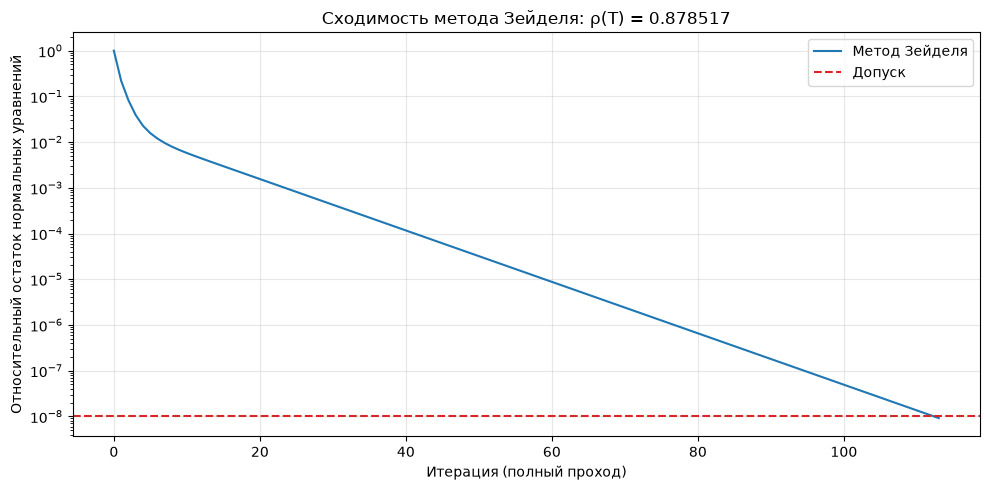

In [22]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.semilogy(history_seidel["Итерация"], history_seidel["Относительный остаток"],
            label="Метод Зейделя")
ax.axhline(tol_seidel, color="tab:red", linestyle="--", label="Допуск")
ax.set(xlabel="Итерация (полный проход)", ylabel="Относительный остаток нормальных уравнений",
       title=f"Сходимость метода Зейделя: ρ(T) = {rho_seidel:.6f}")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

### Что проверяем по результатам

| Показатель | Что показывает |
|---|---|
| $\|A\beta-b\|_2/\|b\|_2$ | Насколько точно решена система для коэффициентов |
| $\|\widetilde X\beta-y\|_2/\|y\|_2$ | Насколько прогнозы расходятся с ответами относительно масштаба ответов |
| $\mathrm{RMSE}=\sqrt{\frac1m\sum_{i=1}^{m}(\widehat y_i-y_i)^2}$ | Масштаб ошибки прогноза в кельвинах для $m$ объектов |

Даже у точного решения МНК остается ошибка прогноза. Например, лучший постоянный прогноз для ответов 10, 20, 30 равен 20. Он все равно ошибается на первом и последнем объектах.

Для test используем параметры StandardScaler с train и добавляем столбец единиц. Допуск и число итераций по test не подбираем. В таблице коэффициентов первая строка соответствует свободному члену, остальные строки соответствуют восьми стандартизованным признакам.

In [23]:
# На test используем средние и масштабы, найденные на train.
X_test_std_seidel = scaler.transform(X_test)
X_test_seidel = np.column_stack((np.ones(len(X_test_std_seidel)), X_test_std_seidel))
pred_train_seidel = X_train_seidel @ beta_seidel
pred_test_seidel = X_test_seidel @ beta_seidel
# Остаток СЛАУ берем из истории решателя, ошибки прогноза считаем по температурам.
metrics_seidel = pd.DataFrame([{
    "Метод": "Зейдель",
    "Итераций": n_iter_seidel,
    "ρ(T)": rho_seidel,
    "Относительный остаток СЛАУ": residuals_seidel[-1],
    "Относительный остаток МНК": np.linalg.norm(pred_train_seidel - y_train.to_numpy()) / np.linalg.norm(y_train),
    "RMSE train, К": np.sqrt(np.mean((pred_train_seidel - y_train.to_numpy()) ** 2)),
    "RMSE test, К": np.sqrt(np.mean((pred_test_seidel - y_test.to_numpy()) ** 2)),
    "Статус": status_seidel,
}])
with pd.option_context("display.max_columns", None):
    display(metrics_seidel)
display(pd.DataFrame({"Коэффициент": coefficient_names_seidel, "Коэффициент Зейделя": beta_seidel}))

,Метод,Итераций,ρ(T),Относительный остаток СЛАУ,Относительный остаток МНК,"RMSE train, К","RMSE test, К",Статус
0,Зейдель,113,0.878517,9.149577e-09,0.495452,24.215527,24.039135,Достигнут допуск


,Коэффициент,Коэффициент Зейделя
0,Свободный член,34.737074
1,mean_atomic_mass,12.134184
2,mean_fie,15.547587
3,mean_atomic_radius,12.204314
4,mean_Density,-18.848016
5,mean_ElectronAffinity,-6.675542
6,mean_FusionHeat,-2.114263
7,mean_ThermalConductivity,13.070520
8,mean_Valence,-2.868116


### Вывод

Получили $\rho(T)\approx0{,}878517<1$, поэтому ожидали сходимость. Метод достиг допуска за 113 проходов. Остаток снизился с 1 до $9{,}15\cdot10^{-9}$. После первых шагов линия на логарифмическом графике стала почти прямой.

Свободный член равен 34,7371 К и совпадает со средней температурой на train. RMSE получился около 24 К на обеих выборках. Малый остаток системы показывает, что мы точно нашли коэффициенты МНК. RMSE показывает, насколько хорошо сама линейная модель описывает температуру.

## 1.4.4. Решение на основе SVD

### Решение задачи МНК через SVD

Решаем задачу наименьших квадратов на тех же восьми стандартизованных признаках и том же разбиении данных, что в пунктах 1.4.2 и 1.4.3. Для учёта свободного члена добавляем **первым столбцом единицы**:

$$
X=[\mathbf{1},X_{\mathrm{train,std}}],
\qquad y=y_{\mathrm{train}}.
$$

Расширенная матрица содержит девять столбцов, а вектор коэффициентов — свободный член и восемь весов признаков:

$$
\beta=(\beta_0,\beta_1,\ldots,\beta_8)^\top.
$$

Решаем задачу:

$$
\min_{\beta\in\mathbb{R}^{9}}\|X\beta-y\|_2^2.
$$

Используем готовую матрицу `X_train_std`. Тестовые признаки преобразуем методом `scaler.transform`, применяя параметры стандартизации, вычисленные только по обучающей части, после чего также добавляем первым столбцом единицы. **Столбец единиц не стандартизируем**, целевую переменную не центрируем.

### SVD и псевдообратное решение

С помощью `numpy.linalg.svd` строим компактное сингулярное разложение расширенной обучающей матрицы:

$$
X=U\Sigma V^\top,
$$

где столбцы \(U\) и \(V\) ортонормированы, а диагональные элементы \(\Sigma\) — сингулярные числа \(\sigma_i\). Параметр `full_matrices=False` позволяет не формировать полную квадратную матрицу \(U\).

Численный ранг определяем по правилу:

$$
\tau=\sigma_{\max}\max(n,p)\varepsilon_{\mathrm{mach}},
\qquad
r_{\mathrm{num}}=\#\{i:\sigma_i>\tau\},
$$

где \(n\) — число обучающих наблюдений, \(p=9\) — число столбцов расширенной матрицы, \(\varepsilon_{\mathrm{mach}}\) — машинная точность. Сингулярные числа, не превышающие допуск, считаем численно нулевыми.

Для построения псевдообратного решения задаём:

$$
(\Sigma^+)_{ii}=
\begin{cases}
1/\sigma_i, & \sigma_i>\tau,\\
0, & \sigma_i\leq\tau.
\end{cases}
$$

Коэффициенты вычисляем по формуле:

$$
\beta_{\mathrm{SVD}}=V\Sigma^+U^\top y.
$$

Полную псевдообратную матрицу не формируем: последовательно выполняем матрично-векторные операции. Коэффициенты получаем непосредственно через SVD матрицы \(X\), что позволяет избежать дополнительного ухудшения обусловленности при формировании \(X^\top X\).

### Сравнение с другими методами

Сопоставляем SVD с методами Гаусса и Зейделя, использующими те же данные и тот же порядок столбцов: сначала единицы, затем восемь стандартизованных признаков. Для каждого решения вычисляем относительный остаток нормальных уравнений и относительный остаток исходной задачи МНК:

$$
r_{\mathrm{NE}}=
\frac{\|X^\top X\beta-X^\top y\|_2}{\|X^\top y\|_2},
\qquad
r_{\mathrm{LS}}=
\frac{\|X\beta-y\|_2}{\|y\|_2},
$$

а также RMSE на обучающей и тестовой частях. Все относительные остатки вычисляются в евклидовой норме; при нулевом знаменателе используется абсолютная норма остатка.

Относительное различие векторов коэффициентов, включая свободный член, оцениваем относительно SVD:

$$
\delta_\beta=
\frac{\|\beta-\beta_{\mathrm{SVD}}\|_2}
{\|\beta_{\mathrm{SVD}}\|_2}.
$$

Результаты представляем в таблице метрик и отдельной таблице коэффициентов. Первый коэффициент соответствует свободному члену, остальные — стандартизованным признакам. RMSE выражается в исходных единицах целевой переменной — кельвинах.

In [24]:
import numpy as np
import pandas as pd
from IPython.display import display

# StandardScaler уже обучен на восьми исходных признаках.
# Единицы добавляем ПОСЛЕ стандартизации, первым столбцом.
X_svd = np.column_stack((
    np.ones(len(X_train_std)),
    X_train_std,
))
X_test_svd = np.column_stack((
    np.ones(len(X_test)),
    scaler.transform(X_test),
))

y_svd = y_train.to_numpy(dtype=np.float64)
y_test_svd = y_test.to_numpy(dtype=np.float64)
coefficient_names_svd = ["Свободный член"] + list(FEATURES)

assert X_svd.shape[1] == len(coefficient_names_svd)

# SVD расширенной матрицы: 1 свободный член + 8 признаков.
U_svd, s_svd, Vt_svd = np.linalg.svd(
    X_svd, full_matrices=False
)

# Правило численного ранга сохраняется.
tol_svd = (
    s_svd[0] * max(X_svd.shape)
    * np.finfo(s_svd.dtype).eps
)
keep_svd = s_svd > tol_svd
rank_svd = int(keep_svd.sum())

# Псевдообратное решение без формирования полной псевдообратной.
s_inv_svd = np.zeros_like(s_svd)
s_inv_svd[keep_svd] = 1.0 / s_svd[keep_svd]

beta_svd = Vt_svd.T @ (
    s_inv_svd * (U_svd.T @ y_svd)
)

print(f"Численный ранг: {rank_svd} из {X_svd.shape[1]}")
print(f"Допуск: {tol_svd:.6e}")
print(f"Свободный член: {beta_svd[0]:.6f} К")
print(f"Среднее y_train: {y_svd.mean():.6f} К")

display(pd.DataFrame({
    "Сингулярное число": s_svd,
    "Сохранено": keep_svd,
}))

# Нормальные уравнения нужны только для измерения остатка.
A_svd = X_svd.T @ X_svd
b_svd = X_svd.T @ y_svd


def relative_norm_svd(residual, reference):
    denominator = np.linalg.norm(reference)
    if denominator > 0:
        return np.linalg.norm(residual) / denominator
    return np.linalg.norm(residual)


# Результаты коллег должны относиться к той же расширенной матрице:
# первым столбцом идут единицы, далее — восемь признаков FEATURES.
solutions_svd = {
    "Гаусс": globals().get("beta_gauss"),
    "Зейдель": globals().get("beta_seidel"),
    "SVD": beta_svd,
}
statuses_svd = {
    "Гаусс": globals().get("direct_status", {}).get(
        "Гаусс", "Нет результата"
    ),
    "Зейдель": globals().get("status_seidel", "Нет результата"),
    "SVD": "Успех",
}

rows_svd = []
coefficients_svd = {}

for method, beta in solutions_svd.items():
    row = {"Метод": method, "Статус": statuses_svd[method]}

    if beta is None:
        rows_svd.append(row)
        continue

    beta = np.asarray(beta, dtype=np.float64)

    # Старые решения содержат 8 коэффициентов, новые — 9.
    # Их нельзя включать в общее сравнение одной модели.
    if beta.shape != beta_svd.shape:
        row["Статус"] = (
            "Не сравнивается: пересчитайте "
            "с единицами первым столбцом"
        )
        rows_svd.append(row)
        continue

    if not np.isfinite(beta).all():
        row["Статус"] = "Не сравнивается: нечисловые коэффициенты"
        rows_svd.append(row)
        continue

    pred_train = X_svd @ beta
    pred_test = X_test_svd @ beta

    row.update({
        "Отличие β от SVD":
            relative_norm_svd(beta - beta_svd, beta_svd),
        "Относительный остаток СЛАУ":
            relative_norm_svd(A_svd @ beta - b_svd, b_svd),
        "Относительный остаток МНК":
            relative_norm_svd(pred_train - y_svd, y_svd),
        "RMSE train, К":
            np.sqrt(np.mean((pred_train - y_svd) ** 2)),
        "RMSE test, К":
            np.sqrt(np.mean((pred_test - y_test_svd) ** 2)),
    })

    rows_svd.append(row)
    coefficients_svd[method] = beta

comparison_svd = pd.DataFrame(rows_svd)
coefficients_svd = pd.DataFrame(
    coefficients_svd,
    index=coefficient_names_svd,
)

with pd.option_context(
    "display.max_columns", None,
    "display.float_format", "{:.6e}".format,
):
    display(comparison_svd)
    display(coefficients_svd)

Численный ранг: 9 из 9
Допуск: 6.677926e-10
Свободный член: 34.737074 К
Среднее y_train: 34.737074 К


,Сингулярное число,Сохранено
0,202.060640,True
1,176.373633,True
2,129.671406,True
3,122.000000,True
4,121.163314,True
5,83.259186,True
6,67.083801,True
7,57.325417,True
8,30.365860,True


,Метод,Статус,Отличие β от SVD,Относительный остаток СЛАУ,Относительный остаток МНК,"RMSE train, К","RMSE test, К"
0,Гаусс,Успех,3.249448e-15,1.622452e-16,4.954521e-01,2.421553e+01,2.403914e+01
1,Зейдель,Достигнут допуск,1.071454e-07,9.149577e-09,4.954521e-01,2.421553e+01,2.403913e+01
2,SVD,Успех,0.000000e+00,2.229064e-15,4.954521e-01,2.421553e+01,2.403914e+01


,Гаусс,Зейдель,SVD
Свободный член,3.473707e+01,3.473707e+01,3.473707e+01
mean_atomic_mass,1.213419e+01,1.213418e+01,1.213419e+01
mean_fie,1.554759e+01,1.554759e+01,1.554759e+01
mean_atomic_radius,1.220431e+01,1.220431e+01,1.220431e+01
mean_Density,-1.884802e+01,-1.884802e+01,-1.884802e+01
mean_ElectronAffinity,-6.675543e+00,-6.675542e+00,-6.675543e+00
mean_FusionHeat,-2.114263e+00,-2.114263e+00,-2.114263e+00
mean_ThermalConductivity,1.307052e+01,1.307052e+01,1.307052e+01
mean_Valence,-2.868114e+00,-2.868116e+00,-2.868114e+00


### Вывод

Для обучающей матрицы, содержащей столбец единиц и восемь стандартизованных признаков, построено компактное SVD и получено псевдообратное решение задачи МНК. При допуске \(6{,}68\cdot10^{-10}\) численный ранг составил **9 из 9**: все сингулярные числа сохранены, решение МНК единственно. Число обусловленности расширенной матрицы составляет примерно \(6{,}65\).

Свободный член равен **34,737074 К** и совпадает со средним значением целевой переменной на обучающей части. Это согласуется с центрированием обучающих признаков при стандартизации.

Решения Гаусса и SVD практически совпадают: относительное различие коэффициентов имеет порядок $10^{-15}$. Для метода Зейделя различие равно \(1{,}07\cdot10^{-7}\), что объясняется остановкой итераций при достижении заданного допуска. Относительный остаток нормальных уравнений для SVD имеет порядок $10^{-15}$, подтверждая высокую точность решения системы.

Все три метода дают практически одинаковые результаты: относительный остаток МНК равен \(0{,}4954521\), RMSE на обучающей части — около **24,21553 К**, на тестовой — **24,03914 К**. При этом малый остаток нормальных уравнений характеризует точность численного решения, а RMSE — качество прогноза выбранной модели.

## 1.4.5. Ухудшение обусловленности

Добавим новый признак как линейная комбинация двух + центрированный шум с дисперсией 1.

In [25]:
EPSILONS_CONDITIONING = (1e-2, 1e-6, 0.0)
SEED_CONDITIONING = SEED
J_CONDITIONING, K_CONDITIONING = 0, 1
C_CONDITIONING = 1.0

X_train_conditioning_base = np.asarray(X_train_std, dtype=np.float64)
X_test_conditioning_base = scaler.transform(X_test)
y_train_conditioning = y_train.to_numpy(dtype=np.float64)
y_test_conditioning = y_test.to_numpy(dtype=np.float64)

rng_conditioning = np.random.default_rng(SEED_CONDITIONING)
z_train_conditioning = rng_conditioning.standard_normal(len(X_train_conditioning_base))
z_mean_conditioning = z_train_conditioning.mean()
z_scale_conditioning = z_train_conditioning.std(ddof=0)
z_train_conditioning = (z_train_conditioning - z_mean_conditioning) / z_scale_conditioning
z_test_conditioning = (
    rng_conditioning.standard_normal(len(X_test_conditioning_base)) - z_mean_conditioning
) / z_scale_conditioning

coefficient_names_conditioning = ["Свободный член"] + list(FEATURES) + ["x_new"]

display(pd.DataFrame([{
    "x_j": FEATURES[J_CONDITIONING],
    "x_k": FEATURES[K_CONDITIONING],
    "c": C_CONDITIONING,
    "Seed": SEED_CONDITIONING,
    "Среднее z_train": z_train_conditioning.mean(),
    "Дисперсия z_train": z_train_conditioning.var(ddof=0),
}]))


,x_j,x_k,c,Seed,Среднее z_train,Дисперсия z_train
0,mean_atomic_mass,mean_fie,1.0,42,-1.623116e-17,1.0


Добавляем bias признак + новый признак

In [26]:
rows_conditioning = []
conditioning_solutions = {}
conditioning_spectra = {}

for epsilon_conditioning in EPSILONS_CONDITIONING:
    x_new_train_conditioning = (
        X_train_conditioning_base[:, J_CONDITIONING]
        + C_CONDITIONING * X_train_conditioning_base[:, K_CONDITIONING]
        + epsilon_conditioning * z_train_conditioning
    )
    x_new_test_conditioning = (
        X_test_conditioning_base[:, J_CONDITIONING]
        + C_CONDITIONING * X_test_conditioning_base[:, K_CONDITIONING]
        + epsilon_conditioning * z_test_conditioning
    )
    X_train_conditioning = np.column_stack((
        np.ones(len(X_train_conditioning_base)),
        X_train_conditioning_base,
        x_new_train_conditioning,
    ))
    X_test_conditioning = np.column_stack((
        np.ones(len(X_test_conditioning_base)),
        X_test_conditioning_base,
        x_new_test_conditioning,
    ))
    A_conditioning = X_train_conditioning.T @ X_train_conditioning
    b_conditioning = X_train_conditioning.T @ y_train_conditioning
    rtol_conditioning = A_conditioning.shape[0] * np.finfo(A_conditioning.dtype).eps
    pivot_tol_conditioning = rtol_conditioning * np.linalg.norm(A_conditioning, ord=np.inf)

    rank_conditioning = np.nan
    tol_conditioning = np.nan
    cond_X_conditioning = np.nan
    sigma_min_conditioning = np.nan
    svd_error_conditioning = None

    try:
        U_conditioning, s_conditioning, Vt_conditioning = np.linalg.svd(
            X_train_conditioning, full_matrices=False
        )
        tol_conditioning = (
            s_conditioning[0] * max(X_train_conditioning.shape)
            * np.finfo(s_conditioning.dtype).eps
        )
        keep_conditioning = s_conditioning > tol_conditioning
        rank_conditioning = int(keep_conditioning.sum())
        sigma_min_conditioning = s_conditioning[-1]
        cond_X_conditioning = (
            s_conditioning[0] / s_conditioning[-1]
            if rank_conditioning == X_train_conditioning.shape[1]
            else np.inf
        )
        conditioning_spectra[epsilon_conditioning] = s_conditioning.copy()
    except (np.linalg.LinAlgError, FloatingPointError, ValueError) as error:
        svd_error_conditioning = str(error)

    for method_conditioning in ("Гаусс", "SVD"):
        row_conditioning = {
            "ε": epsilon_conditioning,
            "Метод": method_conditioning,
            "Число столбцов X": X_train_conditioning.shape[1],
            "Численный ранг X": rank_conditioning,
            "Допуск ранга": tol_conditioning,
            "σ_min(X)": sigma_min_conditioning,
            "κ₂(X)": cond_X_conditioning,
            "κ₂(XᵀX) = κ₂(X)²": cond_X_conditioning ** 2,
            "Порог pivot Гаусса": pivot_tol_conditioning,
            "‖β‖₂": np.nan,
            "Относительный остаток СЛАУ": np.nan,
            "Относительный остаток МНК": np.nan,
            "RMSE test, К": np.nan,
            "Статус": "",
        }
        try:
            with np.errstate(over="raise", divide="raise", invalid="raise"):
                if method_conditioning == "Гаусс":
                    beta_conditioning = gaussian_solve(
                        A_conditioning, b_conditioning, rtol=rtol_conditioning
                    )
                else:
                    if svd_error_conditioning is not None:
                        raise np.linalg.LinAlgError(svd_error_conditioning)
                    beta_conditioning = Vt_conditioning[keep_conditioning].T @ (
                        (U_conditioning[:, keep_conditioning].T @ y_train_conditioning)
                        / s_conditioning[keep_conditioning]
                    )
                if not np.isfinite(beta_conditioning).all():
                    raise FloatingPointError("Получены нечисловые коэффициенты.")
                pred_train_conditioning = X_train_conditioning @ beta_conditioning
                pred_test_conditioning = X_test_conditioning @ beta_conditioning
                row_conditioning.update({
                    "‖β‖₂": np.linalg.norm(beta_conditioning),
                    "Относительный остаток СЛАУ": relative_norm(
                        A_conditioning @ beta_conditioning - b_conditioning, b_conditioning
                    ),
                    "Относительный остаток МНК": relative_norm(
                        pred_train_conditioning - y_train_conditioning, y_train_conditioning
                    ),
                    "RMSE test, К": np.sqrt(np.mean(
                        (pred_test_conditioning - y_test_conditioning) ** 2
                    )),
                    "Статус": "Успех",
                })
                conditioning_solutions[(epsilon_conditioning, method_conditioning)] = (
                    beta_conditioning.copy()
                )
        except (np.linalg.LinAlgError, FloatingPointError, ValueError) as error:
            row_conditioning["Статус"] = f"{type(error).__name__}: {error}"
        rows_conditioning.append(row_conditioning)

conditioning_results = pd.DataFrame(rows_conditioning)
conditioning_coefficients = pd.DataFrame(
    conditioning_solutions, index=coefficient_names_conditioning
)
conditioning_coefficients.columns = pd.MultiIndex.from_tuples(
    conditioning_coefficients.columns, names=["ε", "Метод"]
)


In [27]:
with pd.option_context(
    "display.max_columns", None,
    "display.max_colwidth", None,
    "display.float_format", "{:.6e}".format,
):
    display(conditioning_results)
    display(conditioning_coefficients)


,ε,Метод,Число столбцов X,Численный ранг X,Допуск ранга,σ_min(X),κ₂(X),κ₂(XᵀX) = κ₂(X)²,Порог pivot Гаусса,‖β‖₂,Относительный остаток СЛАУ,Относительный остаток МНК,"RMSE test, К",Статус
0,1.000000e-02,Гаусс,10,10,7.105360e-10,7.042672e-01,3.052733e+02,9.319176e+04,1.572383e-10,6.255486e+01,3.952883e-16,4.954419e-01,2.403786e+01,Успех
1,1.000000e-02,SVD,10,10,7.105360e-10,7.042672e-01,3.052733e+02,9.319176e+04,1.572383e-10,6.255486e+01,9.104839e-16,4.954419e-01,2.403786e+01,Успех
2,1.000000e-06,Гаусс,10,10,7.105414e-10,7.042205e-05,3.052958e+06,9.320553e+12,1.572357e-10,2.691836e+05,1.925416e-12,4.954419e-01,2.403786e+01,Успех
3,1.000000e-06,SVD,10,10,7.105414e-10,7.042205e-05,3.052958e+06,9.320553e+12,1.572357e-10,2.692712e+05,4.597379e-12,4.954419e-01,2.403786e+01,Успех
4,0.000000e+00,Гаусс,10,9,7.105414e-10,1.621578e-14,inf,inf,1.572357e-10,NaN,NaN,NaN,NaN,LinAlgError: Малый ведущий элемент на шаге 10: 2.000888e-11 <= 1.572357e-10
5,0.000000e+00,SVD,10,9,7.105414e-10,1.621578e-14,inf,inf,1.572357e-10,4.552465e+01,1.151810e-15,4.954521e-01,2.403914e+01,Успех


ε                         1.000000e-02                1.000000e-06  \
Метод                            Гаусс           SVD         Гаусс   
Свободный член            3.473707e+01  3.473707e+01  3.473707e+01   
mean_atomic_mass          2.767600e+01  2.767600e+01  1.554161e+05   
mean_fie                  3.109111e+01  3.109111e+01  1.554195e+05   
mean_atomic_radius        1.220361e+01  1.220361e+01  1.220361e+01   
mean_Density             -1.884548e+01 -1.884548e+01 -1.884549e+01   
mean_ElectronAffinity    -6.673620e+00 -6.673620e+00 -6.673620e+00   
mean_FusionHeat          -2.117694e+00 -2.117694e+00 -2.117693e+00   
mean_ThermalConductivity  1.307063e+01  1.307063e+01  1.307063e+01   
mean_Valence             -2.867708e+00 -2.867708e+00 -2.867708e+00   
x_new                    -1.554546e+01 -1.554546e+01 -1.554040e+05   

ε                                       0.000000e+00  
Метод                              SVD           SVD  
Свободный член            3.473707e+01  3.473707e+01  
mean_atomic_mass          1.554667e+05  2.906928e+00  
mean_fie                  1.554701e+05  6.320330e+00  
mean_atomic_radius        1.220361e+01  1.220431e+01  
mean_Density             -1.884548e+01 -1.884802e+01  
mean_ElectronAffinity    -6.673620e+00 -6.675543e+00  
mean_FusionHeat          -2.117694e+00 -2.114263e+00  
mean_ThermalConductivity  1.307063e+01  1.307052e+01  
mean_Valence             -2.867708e+00 -2.868114e+00  
x_new                    -1.554546e+05  9.227258e+00

При Epsilon = 0 численный ранг не равен полному рангу, так как добавляется признак как линейная комбинация других признаков без шума. В таком случае минмальное сингулярное число меньше порога и эквивалентно нулю, а значит число обусловленности бесконечно большое, а параметры нельзя интерпретировать однозначно, так как решение beta становится не единственным, то есть ненулевой веткор beta такой, что X @ beta = 0, а значит если beta0 - решение, то beta0 + alpha * beta1 тоже решение так как X@(beta0 + alpha* beta1) = X @ beta0 + alpha * X @ beta1 = X @ beta0, при этом alpha может быть каким угодно большим

## 1.4.6. Сокращение размерности

### Усечённое SVD и сохранение свободного члена

Исследуем $k=1,2,3$ и полный численный ранг восьми стандартизованных признаков. Используем исходные признаки, без искусственного столбца `x_new` из 1.4.5. Разбиение и параметры `StandardScaler` сохраняем. Преобразование строим только по train, тестовая часть не участвует в поиске направлений или подборе параметров.

Разлагаем матрицу $X=X_{train,std}$ без столбца единиц:

$$X=U\Sigma V^T.$$

Ранг определяем по допуску $\tau=\sigma_{max}\max(n,p)\varepsilon_{mach}$. Сохраняем первые $k$ направлений $V_k$, соответствующих наибольшим сингулярным числам. Новые признаки равны

$$Z_{train,k}=X_{train,std}V_k,\qquad Z_{test,k}=X_{test,std}V_k.$$

Это линейные комбинации всех восьми признаков, а не выбор отдельных исходных столбцов. Поскольку обучающие признаки центрированы, свободный член равен $\beta_0=\overline y_{train}$. Он сохраняется во всех моделях и не участвует в усечении. Временное центрирование ответов ниже нужно только для расчёта весов, прогнозы возвращаются в исходную шкалу добавлением свободного члена:

$$\theta_k=\Sigma_k^{-1}U_k^T(y_{train}-\overline y_{train}\mathbf1),\qquad
\hat y=\overline y_{train}\mathbf1+Z_k\theta_k.$$

Для каждого $k$ вычисляем сохранённую долю дисперсии признаков и относительную ошибку приближения в норме Фробениуса:

$$q_k=\frac{\sum_{i=1}^k\sigma_i^2}{\sum_i\sigma_i^2},\qquad
 e_k=\frac{\|X-X_k\|_F}{\|X\|_F}
 =\sqrt{\frac{\sum_{i>k}\sigma_i^2}{\sum_i\sigma_i^2}}.$$

Обусловленность измеряем для фактической редуцированной матрицы регрессии $B_k=[\mathbf1,Z_{train,k}]$, то есть включая свободный член. Дополнительно сохраняем RMSE на train и test. Число $k$ в таблице относится только к сингулярным направлениям признаков, полное число параметров модели равно $k+1$.

Используется библиотечное разложение [numpy.linalg.svd](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html); усечение, расчёт коэффициентов и метрик выполнены явно.

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Берём исходные 8 признаков, без x_new из пункта 1.4.5.
# Готовый scaler повторно не обучаем.
X_train_tsvd = np.asarray(X_train_std, dtype=np.float64)
X_test_tsvd = scaler.transform(X_test)
y_train_tsvd = y_train.to_numpy(dtype=np.float64)
y_test_tsvd = y_test.to_numpy(dtype=np.float64)

# Столбец единиц не включаем в сокращение размерности.
U_tsvd, s_tsvd, Vt_tsvd = np.linalg.svd(
    X_train_tsvd, full_matrices=False
)
tol_tsvd = (
    s_tsvd[0] * max(X_train_tsvd.shape)
    * np.finfo(s_tsvd.dtype).eps
)
rank_tsvd = int(np.count_nonzero(s_tsvd > tol_tsvd))
assert rank_tsvd >= 3, "Для k = 1, 2, 3 нужен ранг не меньше 3."
assert np.allclose(X_train_tsvd.mean(axis=0), 0, atol=1e-12)
k_values_tsvd = sorted({1, 2, 3, rank_tsvd})

# При центрированных признаках свободный член равен среднему y_train.
intercept_tsvd = float(y_train_tsvd.mean())
y_centered_tsvd = y_train_tsvd - intercept_tsvd
spectrum_energy_tsvd = np.sum(s_tsvd ** 2)
results_rows_tsvd = []
models_tsvd = {}

for k_tsvd in k_values_tsvd:
    # Направления вычислены только по train; test использует те же V_k.
    V_k_tsvd = Vt_tsvd[:k_tsvd].T
    Z_train_tsvd = X_train_tsvd @ V_k_tsvd
    Z_test_tsvd = X_test_tsvd @ V_k_tsvd

    # Коэффициенты МНК по сохранённым сингулярным направлениям.
    theta_tsvd = (
        U_tsvd[:, :k_tsvd].T @ y_centered_tsvd
    ) / s_tsvd[:k_tsvd]
    pred_train_tsvd = intercept_tsvd + Z_train_tsvd @ theta_tsvd
    pred_test_tsvd = intercept_tsvd + Z_test_tsvd @ theta_tsvd

    # Матрица фактической задачи регрессии, включая свободный член.
    B_train_tsvd = np.column_stack((
        np.ones(len(Z_train_tsvd)), Z_train_tsvd
    ))
    explained_tsvd = (
        np.sum(s_tsvd[:k_tsvd] ** 2) / spectrum_energy_tsvd
    )
    approximation_error_tsvd = np.sqrt(
        np.sum(s_tsvd[k_tsvd:] ** 2) / spectrum_energy_tsvd
    )
    results_rows_tsvd.append({
        "k": k_tsvd,
        "Объяснённая дисперсия, %": 100 * explained_tsvd,
        "Ошибка приближения X": approximation_error_tsvd,
        "κ₂([1, Z_k])": np.linalg.cond(B_train_tsvd),
        "RMSE train, К": np.sqrt(np.mean(
            (pred_train_tsvd - y_train_tsvd) ** 2
        )),
        "RMSE test, К": np.sqrt(np.mean(
            (pred_test_tsvd - y_test_tsvd) ** 2
        )),
    })
    # Сохраняем и веса исходных стандартизованных признаков.
    models_tsvd[k_tsvd] = {
        "directions": V_k_tsvd,
        "theta": theta_tsvd,
        "beta": np.r_[intercept_tsvd, V_k_tsvd @ theta_tsvd],
    }

results_tsvd = pd.DataFrame(results_rows_tsvd)
print(f"Численный ранг признаков: {rank_tsvd}; допуск: {tol_tsvd:.6e}")
print(f"Свободный член всех моделей: {intercept_tsvd:.6f} К")
with pd.option_context("display.max_columns", None,
                       "display.float_format", "{:.6f}".format):
    display(results_tsvd)

# Полный ранг должен воспроизвести решение из пункта 1.4.4.
full_beta_tsvd = models_tsvd[rank_tsvd]["beta"]
assert np.allclose(full_beta_tsvd, beta_svd, rtol=1e-10, atol=1e-10)
assert np.isfinite(results_tsvd.to_numpy()).all()
assert np.all(np.diff(results_tsvd["RMSE train, К"]) <= 1e-10)
print("Проверки пройдены: полный ранг совпадает с SVD из 1.4.4, "
      "RMSE train не возрастает при увеличении k.")


Численный ранг признаков: 8; допуск: 6.677926e-10
Свободный член всех моделей: 34.737074 К


,k,"Объяснённая дисперсия, %",Ошибка приближения X,"κ₂([1, Z_k])","RMSE train, К","RMSE test, К"
0,1,34.288919,0.810624,1.656235,32.011334,31.683031
1,2,60.414002,0.629174,1.656235,28.490123,28.164063
2,3,74.535436,0.504624,1.656235,27.381156,27.013139
3,8,100.000000,0.000000,6.654204,24.215527,24.039135


Проверки пройдены: полный ранг совпадает с SVD из 1.4.4, RMSE train не возрастает при увеличении k.


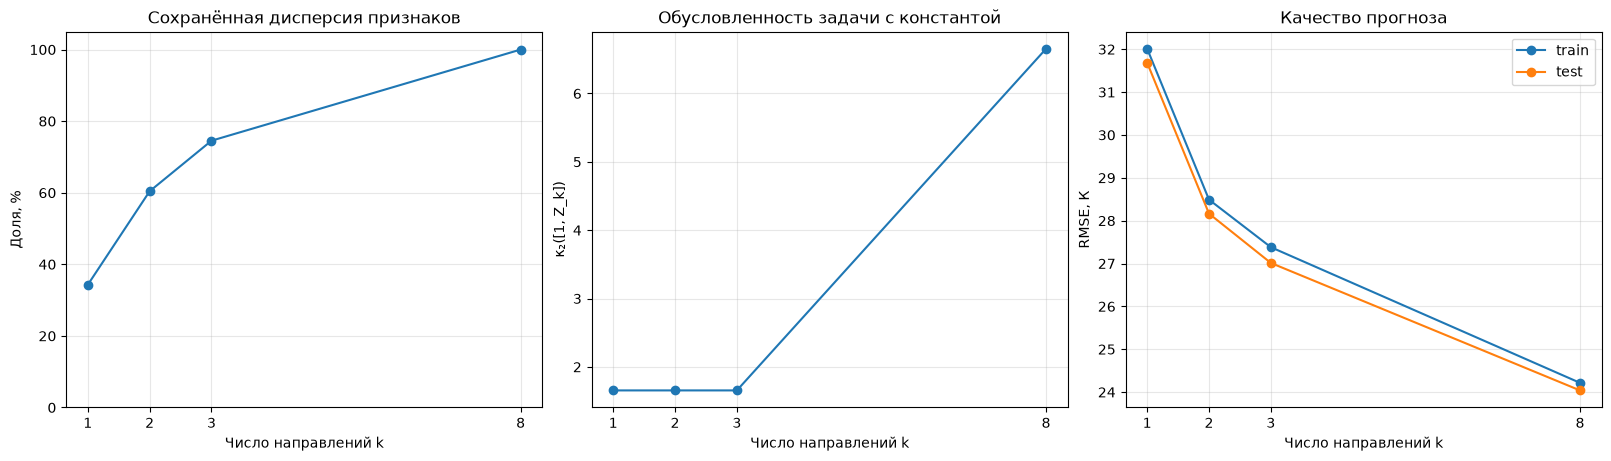

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), layout="constrained")
axes[0].plot(results_tsvd["k"], results_tsvd["Объяснённая дисперсия, %"], "o-")
axes[0].set(xlabel="Число направлений k", ylabel="Доля, %",
            title="Сохранённая дисперсия признаков", ylim=(0, 105))
axes[1].plot(results_tsvd["k"], results_tsvd["κ₂([1, Z_k])"], "o-")
axes[1].set(xlabel="Число направлений k", ylabel="κ₂([1, Z_k])",
            title="Обусловленность задачи с константой")
for split_tsvd in ("train", "test"):
    axes[2].plot(results_tsvd["k"], results_tsvd[f"RMSE {split_tsvd}, К"],
                 "o-", label=split_tsvd)
axes[2].set(xlabel="Число направлений k", ylabel="RMSE, К",
            title="Качество прогноза")
axes[2].legend()
for ax_tsvd in axes:
    ax_tsvd.set_xticks(k_values_tsvd)
    ax_tsvd.grid(alpha=0.3)
plt.show()


### Вывод

Численный ранг матрицы восьми стандартизованных признаков равен 8 при допуске $6{,}68\cdot10^{-10}$. Поэтому сравнивались $k=1,2,3,8$. Свободный член сохранялся во всех моделях и составлял 34,737074 К.

Одно направление сохраняет 34,29% дисперсии признаков, два сохраняют 60,41%, три сохраняют 74,54%. При $k=3$ относительная ошибка приближения исходной матрицы в норме Фробениуса равна примерно 0,5046. Таким образом, сохранение около трёх четвертей дисперсии не означает столь же малой относительной ошибки матрицы, поскольку эта ошибка связана с квадратным корнем из отброшенной доли.

Для $k=1,2,3$ число обусловленности матрицы $[\mathbf1,Z_k]$ равно примерно 1,66, тогда как при полном ранге оно составляет 6,65. Равенство обусловленности первых трёх моделей объясняется тем, что все сохранённые сингулярные числа превышают норму столбца единиц $\sqrt{14884}=122$. Поэтому в этих трёх случаях максимальное сингулярное число равно 202,06, минимальное равно 122.

Улучшение обусловленности сопровождается ростом ошибки прогноза относительно полной модели. RMSE test составляет 31,6830 К при $k=1$, 28,1641 К при $k=2$, 27,0131 К при $k=3$ и 24,0391 К при $k=8$. Ошибка на train также уменьшается при добавлении направлений. Сокращение до трёх направлений улучшает обусловленность примерно в четыре раза, но увеличивает тестовую RMSE примерно на 2,9740 К, или 12,37%.

При полном ранге RMSE train равна 24,2155 К, RMSE test равна 24,0391 К. Коэффициенты совпадают с полным SVD из 1.4.4 с точностью до округлений, что подтверждает корректность реализации.

На данном разбиении усечение до одного, двух или трёх направлений не улучшило качество прогноза. Даже направления с меньшей дисперсией признаков содержат полезную для предсказания информацию. Исходная стандартизованная задача уже имеет умеренную обусловленность, поэтому в выполненном эксперименте сокращение размерности не дало преимущества по RMSE. Тестовая часть использовалась для отчётного сравнения фиксированных вариантов; выбор нового значения $k$ по минимуму тестовой ошибки не проводился.

## 1.4.7. Ridge-регуляризация

### Зачем штрафуем большие веса

Если два признака похожи, большие веса с разными знаками могут компенсировать друг друга. Например, при $x_1=x_2=1$ выражения $2x_1+3x_2$ и $1002x_1-997x_2$ дают 5. Если увеличить только $x_1$ до 1,01, первый прогноз станет 5,02, а второй 15,02.

Ridge добавляет к сумме квадратов ошибок штраф за величину весов.

$$
\min_\beta \left(\|\widetilde X\beta-y\|_2^2+\lambda(\beta_1^2+\cdots+\beta_8^2)\right).
$$

При $\lambda=0$ получаем обычный МНК. Чем больше $\lambda$, тем сильнее штраф за общую величину весов. Отдельный вес при этом может вырасти по модулю. Слишком большой штраф может убрать вклад признаков, полезных для прогноза.

Свободный член $\beta_0$ в штраф не входит. Он по-прежнему равен средней температуре на train, потому что обучающие признаки центрированы. При очень большом $\lambda$ остальные веса стремятся к нулю и прогноз приближается к этому среднему.

Берем те же восемь признаков со StandardScaler, обученным на train, и добавляем столбец единиц. Так штрафуем веса признаков, приведенных к сопоставимому масштабу.

### Как меняется система уравнений

В ridge к матрице обычного МНК добавляем штраф. В коде его задает $D=\operatorname{diag}(0,1,\ldots,1)$. Ноль соответствует свободному члену, восемь единиц соответствуют весам признаков.

$$
A_\lambda\beta_\lambda=b,\qquad
A_\lambda=\widetilde X^T\widetilde X+\lambda D^TD,\qquad
b=\widetilde X^Ty.
$$

В нашей задаче $D^TD$ совпадает с $D$. Поэтому прибавляем $\lambda$ к восьми диагональным элементам и оставляем первый элемент прежним. Правая часть $b$ тоже остается прежней. Систему решаем через np.linalg.solve. У обучающей матрицы полный столбцовый ранг, поэтому $A_\lambda$ положительно определена для любого $\lambda\geq0$.

Здесь ошибка в формуле берется суммой. Если использовать среднюю квадратичную ошибку, для того же баланса между ошибкой и штрафом понадобится другое $\lambda$.

### Как выбираем λ

Пробуем семь значений $\lambda$ от 0,01 до 10000. Каждый следующий шаг увеличивает $\lambda$ в десять раз. Самое маленькое значение должно дать результат, близкий к МНК, а самое большое должно заметно уменьшить общую величину весов.

Для каждого $\lambda$ находим коэффициенты на train. Выбираем $\lambda$ с минимальным RMSE на validation. При равенстве берем меньшее $\lambda$. После выбора используем те же коэффициенты и считаем RMSE на test. Для сравнения в таблице есть ошибки на test и для остальных значений.

В таблице $\kappa_2(A_\lambda)$ показывает, насколько система чувствительна к малым изменениям ее данных. Чем оно больше, тем сильнее могут измениться коэффициенты при небольшом возмущении. Ошибку прогноза проверяем отдельно по RMSE.

Норма $\|\beta\|_2$ учитывает все девять коэффициентов, а $\|D\beta\|_2$ только восемь весов, которые входят в штраф. Для сравнения берем решение МНК из 1.4.4. [Описание ridge в документации scikit-learn](https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression-and-classification).

In [30]:
# Для validation и test используем параметры стандартизации с train.
X_train_ridge = np.column_stack((np.ones(len(X_train)), X_train_std))
X_val_ridge = np.column_stack((np.ones(len(X_val)), scaler.transform(X_val)))
X_test_ridge = np.column_stack((np.ones(len(X_test)), scaler.transform(X_test)))
y_train_ridge = y_train.to_numpy(dtype=float)
y_val_ridge = y_val.to_numpy(dtype=float)
y_test_ridge = y_test.to_numpy(dtype=float)
coefficient_names_ridge = ["Свободный член"] + FEATURES

# Ноль в начале диагонали оставляет свободный член без штрафа.
D_ridge = np.diag(np.r_[0.0, np.ones(len(FEATURES))])
penalty_ridge = D_ridge.T @ D_ridge
A_ridge = X_train_ridge.T @ X_train_ridge
b_ridge = X_train_ridge.T @ y_train_ridge
lambdas_ridge = np.logspace(-2, 4, 7)

# Проверяем, что ridge и SVD используют одну обучающую матрицу.
assert X_train_ridge.shape[1] == 9
assert np.allclose(X_train_ridge, X_svd)
assert np.allclose(penalty_ridge[0], 0)
assert np.linalg.eigvalsh(A_ridge)[0] > 0

print(f"Размер системы: {A_ridge.shape}")
print(f"Значения λ: {lambdas_ridge}")
print("Правило выбора: минимум RMSE на validation.")

Размер системы: (9, 9)
Значения λ: [1.e-02 1.e-01 1.e+00 1.e+01 1.e+02 1.e+03 1.e+04]
Правило выбора: минимум RMSE на validation.


### Что сохраняем после каждого расчета

В ridge_solutions сохраняем коэффициенты по каждому $\lambda$, а из ridge_rows собираем таблицу ошибок и норм. Проверяем, что остаток системы мал и свободный член совпадает со средней температурой на train.

Из таблицы берем строку с наименьшим RMSE на validation. Ее $\lambda$ записываем в best_lambda_ridge, а коэффициенты достаем из ridge_solutions.

In [31]:
def rmse_ridge(prediction, target):
    return float(np.sqrt(np.mean((prediction - target) ** 2)))


ridge_solutions = {}
ridge_rows = []
for lambda_ridge in lambdas_ridge:
    A_regularized_ridge = A_ridge + lambda_ridge * penalty_ridge
    beta_current_ridge = np.linalg.solve(A_regularized_ridge, b_ridge)
    # Проверяем точность решения и совпадение свободного члена со средним y.
    residual_ridge = np.linalg.norm(A_regularized_ridge @ beta_current_ridge - b_ridge) / np.linalg.norm(b_ridge)
    assert residual_ridge < 1e-12
    assert np.isclose(beta_current_ridge[0], y_train_ridge.mean(), atol=1e-10, rtol=0)
    ridge_solutions[float(lambda_ridge)] = beta_current_ridge
    ridge_rows.append({
        "λ": float(lambda_ridge),
        "κ₂(Aλ)": np.linalg.cond(A_regularized_ridge),
        "Норма β": np.linalg.norm(beta_current_ridge),
        "Норма Dβ": np.linalg.norm(D_ridge @ beta_current_ridge),
        "RMSE train, К": rmse_ridge(X_train_ridge @ beta_current_ridge, y_train_ridge),
        "RMSE val, К": rmse_ridge(X_val_ridge @ beta_current_ridge, y_val_ridge),
    })

ridge_results = pd.DataFrame(ridge_rows)
# Сетка идет от меньших λ к большим. При равенстве idxmin берет первое.
best_index_ridge = ridge_results["RMSE val, К"].idxmin()
best_lambda_ridge = float(ridge_results.loc[best_index_ridge, "λ"])
beta_ridge = ridge_solutions[best_lambda_ridge]

# Считаем ошибки на test после выбора λ.
ridge_results["RMSE test, К"] = [
    rmse_ridge(X_test_ridge @ ridge_solutions[value], y_test_ridge)
    for value in ridge_results["λ"]
]
assert np.isfinite(ridge_results.to_numpy()).all()

with pd.option_context("display.max_columns", None, "display.float_format", "{:.6f}".format):
    display(ridge_results)
print(f"Выбрано λ = {best_lambda_ridge:g}")

,λ,κ₂(Aλ),Норма β,Норма Dβ,"RMSE train, К","RMSE val, К","RMSE test, К"
0,0.010000,44.277967,48.248378,33.484947,24.215527,24.657283,24.039134
1,0.100000,44.273744,48.246976,33.482927,24.215527,24.657259,24.039127
2,1.000000,44.231552,48.232978,33.462754,24.215528,24.657023,24.039055
3,10.000000,43.814118,48.094867,33.263371,24.215629,24.654775,24.038438
4,100.000000,40.044110,46.879178,31.480042,24.224128,24.641754,24.040533
5,1000.000000,21.762041,41.784145,23.221766,24.492398,24.792298,24.274803
6,10000.000000,4.653736,37.019680,12.798141,26.207739,26.264234,25.862423


Выбрано λ = 100


### Как читать графики ridge

По горизонтали на каждом графике отложено $\lambda$ в логарифмическом масштабе. Пунктир отмечает значение, выбранное по validation.

Слева видно, как с ростом штрафа снижается число обусловленности. В центре видно, как уменьшаются нормы коэффициентов. На правом графике при больших $\lambda$ ошибка прогноза растет, хотя систему решать численно проще.

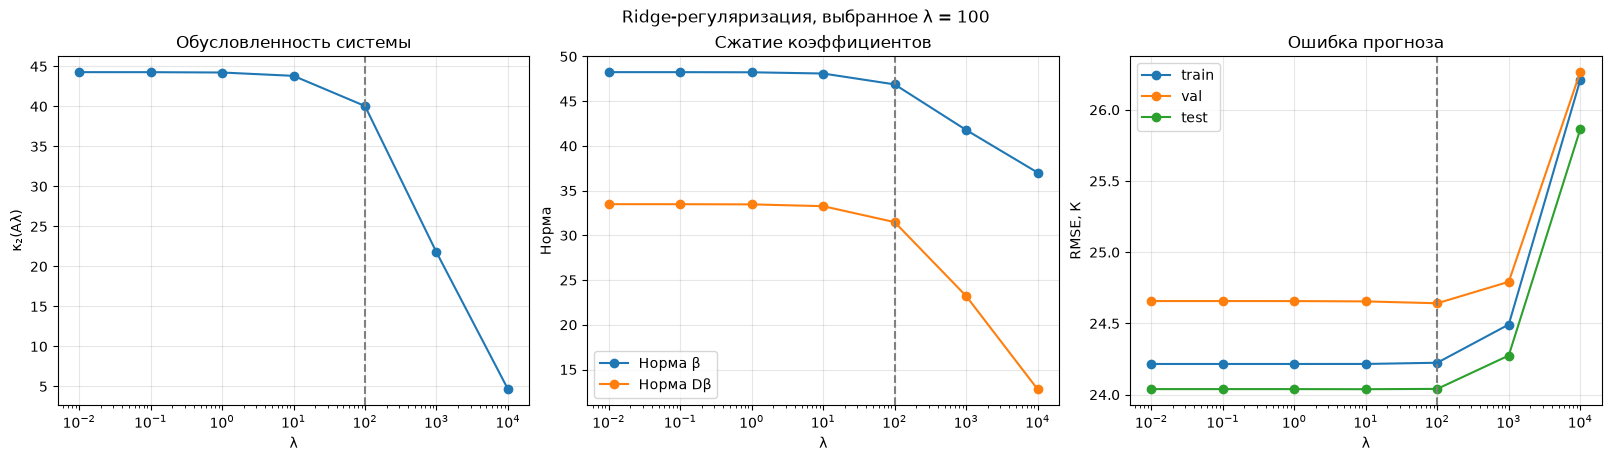

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), layout="constrained")
axes[0].semilogx(ridge_results["λ"], ridge_results["κ₂(Aλ)"], "o-")
axes[0].set(xlabel="λ", ylabel="κ₂(Aλ)", title="Обусловленность системы")

for column in ["Норма β", "Норма Dβ"]:
    axes[1].semilogx(ridge_results["λ"], ridge_results[column], "o-", label=column)
axes[1].set(xlabel="λ", ylabel="Норма", title="Сжатие коэффициентов")
axes[1].legend()

for split in ["train", "val", "test"]:
    axes[2].semilogx(ridge_results["λ"], ridge_results[f"RMSE {split}, К"], "o-", label=split)
axes[2].set(xlabel="λ", ylabel="RMSE, К", title="Ошибка прогноза")
axes[2].legend()
# Пунктир везде отмечает одно и то же λ, выбранное по validation.
for ax in axes:
    ax.axvline(best_lambda_ridge, color="gray", linestyle="--")
    ax.grid(alpha=0.3)
fig.suptitle(f"Ridge-регуляризация, выбранное λ = {best_lambda_ridge:g}")
plt.show()

In [33]:
# В строке для МНК используем коэффициенты из раздела про SVD.
comparison_rows_ridge = []
for method_ridge, beta_comparison_ridge, lambda_comparison_ridge in [
    ("МНК (SVD)", beta_svd, 0.0),
    ("Ridge", beta_ridge, best_lambda_ridge),
]:
    comparison_rows_ridge.append({
        "Метод": method_ridge,
        "λ": lambda_comparison_ridge,
        "κ₂(Aλ)": np.linalg.cond(A_ridge + lambda_comparison_ridge * penalty_ridge),
        "Норма β": np.linalg.norm(beta_comparison_ridge),
        "Норма Dβ": np.linalg.norm(D_ridge @ beta_comparison_ridge),
        "RMSE train, К": rmse_ridge(X_train_ridge @ beta_comparison_ridge, y_train_ridge),
        "RMSE val, К": rmse_ridge(X_val_ridge @ beta_comparison_ridge, y_val_ridge),
        "RMSE test, К": rmse_ridge(X_test_ridge @ beta_comparison_ridge, y_test_ridge),
    })
comparison_ridge = pd.DataFrame(comparison_rows_ridge)
coefficients_ridge = pd.DataFrame(
    {"МНК (SVD)": beta_svd, "Ridge": beta_ridge},
    index=pd.Index(coefficient_names_ridge, name="Коэффициент"),
)
with pd.option_context("display.max_columns", None, "display.float_format", "{:.6f}".format):
    display(comparison_ridge)
    display(coefficients_ridge)

,Метод,λ,κ₂(Aλ),Норма β,Норма Dβ,"RMSE train, К","RMSE val, К","RMSE test, К"
0,МНК (SVD),0.000000,44.278437,48.248534,33.485171,24.215527,24.657286,24.039135
1,Ridge,100.000000,40.044110,46.879178,31.480042,24.224128,24.641754,24.040533


,МНК (SVD),Ridge
Коэффициент,,
Свободный член,34.737074,34.737074
mean_atomic_mass,12.134186,11.091812
mean_fie,15.547588,14.761675
mean_atomic_radius,12.204315,11.706500
mean_Density,-18.848020,-17.217817
mean_ElectronAffinity,-6.675543,-6.226756
mean_FusionHeat,-2.114263,-2.297736
mean_ThermalConductivity,13.070521,12.535777
mean_Valence,-2.868114,-3.919761


### Вывод

При $\lambda=0{,}01$ коэффициенты почти совпали с МНК. По validation выбрали $\lambda=100$. RMSE на validation снизился с 24,6573 до 24,6418 К, а на test у обеих моделей получился примерно 24,04 К. Улучшение на validation на тестовой выборке не повторилось.

При $\lambda=10000$ число обусловленности снизилось примерно с 44,28 до 4,65, а норма штрафуемых весов с 33,48 до 12,80. Свободный член остался равен 34,7371 К. При таком штрафе RMSE на test вырос до 25,8624 К.

# 1.7 Итоговое сравнение и выводы

### Исходная задача

Сначала сравним три способа найти коэффициенты одной модели. У всех одна обучающая матрица со свободным членом. Отличие коэффициентов считаем относительно нормы решения SVD, а оба остатка измеряем на train.

In [34]:
solver_summary = comparison_svd.set_index("Метод")[[
    "Отличие β от SVD", "Относительный остаток СЛАУ", "Относительный остаток МНК",
    "RMSE train, К", "RMSE test, К",
]]
solver_summary = solver_summary.round({"Относительный остаток МНК": 4, "RMSE train, К": 3, "RMSE test, К": 3})
for column in ["Отличие β от SVD", "Относительный остаток СЛАУ"]:
    solver_summary[column] = solver_summary[column].map("{:.2e}".format)
solver_summary

,Отличие β от SVD,Относительный остаток СЛАУ,Относительный остаток МНК,"RMSE train, К","RMSE test, К"
Метод,,,,,
Гаусс,3.25e-15,1.62e-16,0.4955,24.216,24.039
Зейдель,1.07e-07,9.15e-09,0.4955,24.216,24.039
SVD,0.00e+00,2.23e-15,0.4955,24.216,24.039


У Зейделя остаток системы больше, чем у Гаусса и SVD, но все три метода дают одинаковую RMSE до третьего знака. Посмотрим, как меняется ошибка на том же разбиении, если оставить меньше направлений или добавить штраф за большие веса.

In [35]:
rmse_columns = ["RMSE train, К", "RMSE test, К"]
dimension_summary = results_tsvd.set_index("k")[rmse_columns].copy()
dimension_summary.index = [
    "Полное SVD" if k == rank_tsvd else f"Усеченное SVD, k = {k}"
    for k in dimension_summary.index
]
dimension_summary.loc[f"Ridge, λ = {best_lambda_ridge:g}"] = ridge_results.loc[best_index_ridge, rmse_columns]
dimension_summary.rename_axis("Модель").round(3)

,"RMSE train, К","RMSE test, К"
Модель,,
"Усеченное SVD, k = 1",32.011,31.683
"Усеченное SVD, k = 2",28.490,28.164
"Усеченное SVD, k = 3",27.381,27.013
Полное SVD,24.216,24.039
"Ridge, λ = 100",24.224,24.041


### Задача с дополнительным признаком

Теперь к восьми признакам добавлена почти точная или точная сумма двух столбцов. Сравним Гаусса и SVD при одном и том же шуме. Пропуски в строке Гаусса означают, что решатель остановился на малом ведущем элементе.

In [36]:
conditioning_summary = conditioning_results[[
    "ε", "Метод", "Численный ранг X", "κ₂(X)", "‖β‖₂", "Относительный остаток СЛАУ",
    "Относительный остаток МНК", "RMSE test, К",
]].copy()
conditioning_summary["ε"] = conditioning_summary["ε"].map("{:.0e}".format)
# Научная запись оставляет видимыми и большие веса, и малые остатки.
for column in ["κ₂(X)", "‖β‖₂", "Относительный остаток СЛАУ"]:
    conditioning_summary[column] = conditioning_summary[column].map("{:.2e}".format, na_action="ignore")
conditioning_summary.set_index(["ε", "Метод"]).round({"Относительный остаток МНК": 4, "RMSE test, К": 3})

Численный ранг X     κ₂(X)      ‖β‖₂ Относительный остаток СЛАУ  \
ε     Метод                                                                    
1e-02 Гаусс                10  3.05e+02  6.26e+01                   3.95e-16   
      SVD                  10  3.05e+02  6.26e+01                   9.10e-16   
1e-06 Гаусс                10  3.05e+06  2.69e+05                   1.93e-12   
      SVD                  10  3.05e+06  2.69e+05                   4.60e-12   
0e+00 Гаусс                 9       inf       NaN                        NaN   
      SVD                   9       inf  4.55e+01                   1.15e-15   

             Относительный остаток МНК  RMSE test, К  
ε     Метод                                           
1e-02 Гаусс                     0.4954        24.038  
      SVD                       0.4954        24.038  
1e-06 Гаусс                     0.4954        24.038  
      SVD                       0.4954        24.038  
0e+00 Гаусс                        NaN           NaN  
      SVD                       0.4955        24.039

### Вывод

Для прогноза критической температуры оставим МНК через полное SVD по восьми стандартизованным признакам со свободным членом. На test получили RMSE 24,039 К. Усечение до трех направлений подняло ошибку почти на 3 К, а ridge с выбранным на validation штрафом дал практически ту же ошибку, что и МНК.

При почти зависимом признаке даже SVD дало большие по модулю веса при прежнем качестве прогноза. При точной зависимости SVD отбросило нулевое в пределах допуска направление и нашло решение минимальной нормы. Метод Гаусса в этом случае остановился.

### Вклад участников

- **Ибрянов Александр** (1.4.1, 1.4.2, 1.4.5) исследовал ранг и обусловленность до и после стандартизации, решил нормальные уравнения методом Гаусса и проверил разложение Холецкого. Сравнил Гаусса и SVD при добавлении почти зависимого и точно зависимого признака.
- **Соколов Андрей** (1.4.3, 1.4.7) реализовал метод Зейделя, проверил прогноз сходимости по графику остатка и числу итераций. Для ridge подобрал штраф по validation и сравнил коэффициенты и ошибки с обычным МНК.
- **Зелимгер Муслим** (1.4.4, 1.4.6) получил решение МНК через SVD и сравнил его с прямым и итерационным решениями. Проверил, как число оставленных сингулярных направлений влияет на обусловленность и ошибку прогноза.

# 1.8 Вопросы для итогового вывода

### 1. Как стандартизация повлияла на обусловленность матрицы и поведение методов?

После StandardScaler число обусловленности матрицы признаков снизилось примерно с $1{,}25\cdot10^4$ до $6{,}65$, а для матрицы нормальных уравнений с $1{,}56\cdot10^8$ до $44{,}28$. Корреляции при этом сохранились. На стандартизованных признаках Зейдель сошелся. Для исходных признаков его не запускали, поэтому сравнить число итераций не можем.

### 2. Совпали ли решения прямого метода, итерационного метода и SVD? Чем объясняются различия?

Коэффициенты Гаусса и SVD различаются на величину порядка $10^{-15}$ относительно нормы решения SVD. У Зейделя отличие от SVD составляет $1{,}07\cdot10^{-7}$. Зейдель останавливается, как только остаток достигает допуска $10^{-8}$. У всех трех методов одна линейная модель со свободным членом и почти одинаковый RMSE, около $24{,}22$ К на train и $24{,}04$ К на test.

### 3. Соответствовала ли фактическая сходимость итерационного метода спектральному прогнозу?

При $\rho(T)\approx0{,}878517<1$ ожидали сходимость. За 113 итераций остаток снизился с 1 до $9{,}15\cdot10^{-9}$, и условие остановки выполнилось.

### 4. Как приближение к потере ранга повлияло на коэффициенты, остаток и качество прогноза?

Когда уменьшили $\varepsilon$ с $10^{-2}$ до $10^{-6}$, норма коэффициентов SVD выросла примерно с 63 до 269000. Веса двух исходных признаков и их почти точной суммы стали большими и компенсировали друг друга. Относительный остаток нормальных уравнений вырос до порядка $10^{-12}$, но остаток МНК остался около 0,4954, а RMSE на test около 24,038 К.

При $\varepsilon=0$ ранг упал с 10 до 9. Гаусс остановился на малом ведущем элементе. SVD отбросило зависимое направление и дало решение минимальной нормы с RMSE на test 24,039 К. Один и тот же прогноз здесь можно получить при разных наборах коэффициентов.

### 5. Как выбранное сокращение размерности повлияло на устойчивость и ошибку прогноза?

При $k=3$ сохранили 74,54% дисперсии признаков. Число обусловленности матрицы со свободным членом снизилось с 6,65 до 1,66, зато RMSE на test выросла с 24,039 до 27,013 К. При одном и двух направлениях ошибка была еще выше. Значит, среди отброшенных направлений были полезные для прогноза температуры.

### 6. Как изменение λ повлияло на обусловленность, коэффициенты и качество ridge-регрессии?

При увеличении λ в нашем эксперименте уменьшились число обусловленности и норма весов. Свободный член не изменился, поскольку не входил в штраф. Ошибка на train выросла. На validation она сначала немного уменьшилась, а затем выросла. Минимум на validation получен при $\lambda=100$. При слишком большом $\lambda=10000$ норма штрафуемых весов уменьшилась на 62% относительно МНК, но RMSE test вырос до 25,8624 К. Значит, более сильный штраф не обязательно улучшает прогноз.

### 7. Какой способ решения оказался наиболее подходящим для исследованной задачи и почему?

На исходной матрице Гаусс и SVD дают практически одинаковые коэффициенты и RMSE. Зейдель достигает того же качества прогноза за 113 проходов. Для этой задачи выбрали обычный МНК через полное SVD. Оно работает напрямую с матрицей признаков, сохраняет все восемь направлений и позволяет увидеть потерю ранга по сингулярным числам. Усечение повысило ошибку на test, а ridge с выбранным $\lambda=100$ дал почти ту же RMSE, что и МНК.